# Pixel3DMM v2 — загрузка фото кнопкой + папка с данными на каждое фото
**Официальный код:** [SimonGiebenhain/pixel3dmm](https://github.com/SimonGiebenhain/pixel3dmm) (arXiv 2505.00615, ICLR 2026)

Реконструкция FLAME-лица из фото: предобработка (кроп, PIPNet, сегментация, MICA) → сети нормалей и UV → трекинг.
В v2: сначала демо на **одном загруженном фото** (кнопка в интерфейсе), потом — вся папка/zip тем же прогоном.
Результат на Drive: `OUTPUT/<имя батча>/photos/<имя файла>/` — mesh, параметры, лондмарки, кроп, оверлей.

### Как запустить
1. Colab: **Runtime → Upload notebook** → выбери `Pixel3DMM_Colab_v2.ipynb` (именно v2, не старый файл).
2. **Runtime → Change runtime type → GPU: T4/L4** → «Подключиться».
3. Жми ▶︎ по порядку: **0** (загрузка фото) → **1** (конфиг) → **2** (ядро) → **3** (окружение ~40 мин) → **4** (веса) → **5** (preflight) → **6** (демо на фото) → **6b** (показать результат).
4. Папка с фото целиком: **0** грузит `.zip` папки (или используй `MODE = "drive"` и папку на Drive) → **7** plan → **8** run.

### Как выглядит работа
```
[0. ЗАГРУЗКА]        ← кнопка в браузере: одно фото / несколько / .zip с папкой
        ↓
[1. ВХОД -> ВЫХОД]   ← единственная ячейка с ручными параметрами:
                       MODE   = "upload"          (фото кнопкой) | "drive" (папка на Drive)
                       OUTPUT = "MyDrive/pixel3dmm_results"      (куда результат)
                       EXPORT = "photos"          (папка на каждое фото)
        ↓
[2. Ядро]  [3. Окружение ~40 мин]  [4. Веса ~10 мин]        ← идемпотентны, жми повторно
        ↓
[5. preflight] → [6. демо на загруженном фото] → [6b. показать результат]
        ↓
[7. plan] → [8. run] ⇄ [9. status] → [10. collect] → весь корпус + индекс
```
Один прогон считает одно фото ~1–2 мин, папку из N фото — как одного актёра (общая форма,
`is_discontinuous=True`), это быстрее, чем N отдельных прогонов. `run` пропускает готовые батчи,
после обрыва сессии просто жми ту же ячейку заново.

### Подготовка (один раз)
1. Для FLAME нужно принять условия лицензии на https://flame.is.tue.mpg.de/. Если `FLAME2020.zip` уже скачан —
   положи в `MyDrive` или загрузи ячейкой 0. Иначе ячейка 4 скачает модель с HF-зеркала.
   `FLAME2023.zip` необязателен: без `flame2023_no_jaw.pkl` пайплайн использует `use_flame2023=False`.
2. Остальные веса (`uv.ckpt`, `normals.ckpt`, `mica.tar`, `epoch59.pth`, antelopev2/buffalo_l) ячейка 4 тянет
   с HF-зеркала — на файлах автора в Google Drive стоит квота скачиваний.

> ⚠️ Ядро Colab (system python 3.12, torch cu128, nvcc 13.x) pytorch3d/nvdiffrast не собирает. Всё ставится
> и выполняется в изолированный энв `/content/p3dmm-env`; в системный python ничего не ставим.

## 0. Загрузка фото (кнопка в интерфейсе)
Жми ▶︎ — браузер спросит файлы. Можно выбрать **одно фото** (демо-прогон), **несколько фото**
(они пойдут одним актёром: общая форма лица) или **`.zip` с папкой фото** (структура папок внутри
сохраняется: папка = актёр). Браузер не отдаёт обычную папку, поэтому для папки — архив,
а большой корпус проще положить на Drive и поставить `MODE = "drive"` в ячейке 1.
Загруженное ложится в `/content/upload/<имя файла>/`; этот же файл при перезапуске
сессии восстанавливается из архива `OUTPUT/_uploads` автоматически (ячейка 1).

In [2]:
# ╔══════════════════════════════════════════════════════════════════╗
# ║   📤  ЖМИ ▶︎  →  в окне браузера выбери файлы                     ║
# ║       одно фото | несколько фото | .zip с папкой фото            ║
# ╚══════════════════════════════════════════════════════════════════╝
BATCH_NAME = ""              # необязательно: своё имя папки батча (латиница/цифры/пробелы)
import os, pathlib, shutil, time, zipfile
from google.colab import files

UPLOAD = pathlib.Path("/content/upload")     # отсюда читает пайплайн (ячейка 1, MODE="upload")
IMG_EXT = {".jpg", ".jpeg", ".png"}


def junk(name):
    parts = pathlib.PurePosixPath(str(name)).parts
    return parts[-1].startswith("._") or parts[-1] == ".DS_Store" or "__MACOSX" in parts


def is_photo(name):
    return pathlib.PurePosixPath(str(name)).suffix.lower() in IMG_EXT and not junk(name)


def staged(picture):
    """Превью в интерфейсе: то, что реально приехало из браузера."""
    try:
        from IPython.display import Image, display
        display(Image(filename=str(picture), width=260))
    except Exception:
        print("  ", picture.name)


def place(name, data, dest):
    raw = pathlib.Path.cwd() / pathlib.PurePosixPath(str(name)).name
    raw.write_bytes(data)
    dest.mkdir(parents=True, exist_ok=True)
    target = dest / pathlib.PurePosixPath(str(name)).name
    shutil.move(str(raw), target)
    return target


def unpack(archive, dest):
    """zip -> папка фото; один общий корень архива режем, чтобы имя батча не удваивалось."""
    shutil.rmtree(dest, ignore_errors=True)
    dest.mkdir(parents=True, exist_ok=True)
    with zipfile.ZipFile(archive) as zf:
        names = [n.replace("\\", "/") for n in zf.namelist() if not n.endswith("/") and is_photo(n)]
        tops = {n.split("/", 1)[0] for n in names if "/" in n}
        strip = list(tops)[0] + "/" if len(tops) == 1 and all("/" in n for n in names) else ""
        count = 0
        for n in names:
            rel = n[len(strip):] if strip and n.startswith(strip) else n
            target = (dest / rel).resolve()
            if not str(target).startswith(str(dest.resolve()) + os.sep):
                raise ValueError("опасный путь в архиве: " + n)
            target.parent.mkdir(parents=True, exist_ok=True)
            target.write_bytes(zf.read(n))
            count += 1
    return count


print("Выбирай файлы в окне браузера (можно несколько фото или один .zip с папкой)...")
uploaded = files.upload()
if not uploaded:
    print("ничего не загружено — повтори ячейку")
else:
    photos = sorted(n for n in uploaded if is_photo(n))
    archives = sorted(n for n in uploaded if str(n).lower().endswith(".zip"))
    skipped = [n for n in uploaded if n not in photos and n not in archives]
    if skipped:
        print("пропускаю не фото и не zip:", ", ".join(str(s) for s in skipped[:8]))
    for name in archives:
        stem = BATCH_NAME.strip() or pathlib.PurePosixPath(str(name)).stem
        dest = UPLOAD / stem
        archive = place(name, uploaded[name], UPLOAD / "_zips")
        got = unpack(archive, dest)
        archive.unlink()
        print(f"📦 {str(name)}: распаковано фото {got} -> {dest}")
    if photos:
        first = pathlib.PurePosixPath(str(photos[0])).stem
        stem = BATCH_NAME.strip() or (first if len(photos) == 1 else f"{first}_{len(photos)}photos")
        dest = UPLOAD / stem
        shutil.rmtree(dest, ignore_errors=True)
        for name in photos:
            target = place(name, uploaded[name], dest)
            print(f"🖼  {str(name)} -> {dest}")
            staged(target)
        if len(photos) > 1:
            print(f"   {len(photos)} фото = один актёр (общая форма). Разные люди — грузи их разными папками/zip.")
    total = sum(1 for p in UPLOAD.rglob("*") if p.is_file() and is_photo(p)) if UPLOAD.is_dir() else 0
    print("-" * 60)
    print(f"в /content/upload фото всего: {total}")
    print("дальше: ячейка 1 (там уже стоит MODE=\"upload\") → 2 → 3 → 4 → 5 → 6 (демо) → 6b (показать)")

Выбирай файлы в окне браузера (можно несколько фото или один .zip с папкой)...


Saving Архив.zip to Архив.zip
📦 Архив.zip: распаковано фото 76 -> /content/upload/Архив
------------------------------------------------------------
в /content/upload фото всего: 76
дальше: ячейка 1 (там уже стоит MODE="upload") → 2 → 3 → 4 → 5 → 6 (демо) → 6b (показать)


## 1. ВХОД → ВЫХОД
Единственная ячейка с руками правимыми параметрами (после правки — больше нигде). `MODE = "upload"` — вход берётся
из ячейки 0 (загрузка кнопкой); `MODE = "drive"` — вход берётся из `INPUT`, который можно писать как относительный путь от
`MyDrive` (`MyDrive/3pers`, `3pers` — одно и то же) или как абсолютный (`/content/...`). Если папка лежит вложенно
(`MyDrive/sd/3pers`), ячейка найдёт её сама по имени. В `EXPORT = "photos"` на Drive получается
`OUTPUT/<батч>/photos/<имя файла>/` — папка с данными ищется по названию фото. Дальше идут только стадии — пути не дублируются.

In [3]:
# ╔══════════════════════════════════════════════════════════════════╗
# ║   ✏️  ПРАВЬ ТОЛЬКО ЭТИ СТРОКИ                                    ║
# ║                                                                  ║
# ║   РЕЖИМ ВХОДА     ──►  MODE   = "upload" | "drive"               ║
# ║   ФОТО НА ВХОДЕ   ──►  INPUT   = "MyDrive/3pers"   (для drive)   ║
# ║   РЕЗУЛЬТАТ       ◄──  OUTPUT  = "MyDrive/pixel3dmm_results"     ║
# ╚══════════════════════════════════════════════════════════════════╝
MODE   = "upload"                   # "upload" — фото из ячейки 0 (кнопка) | "drive" — папка/zip на Drive
INPUT  = "MyDrive/2pers/vas"          # только для MODE="drive": папка с фото (или .zip / один .jpg / .mp4)
OUTPUT = "MyDrive/pixel3dmm_results"    # папка результата в Drive
EXPORT = "photos"                 # "photos" — своя папка на каждое фото | "bundle" — только архив
DEMO_PHOTOS = 1                   # сколько фото берёт демо-прогон (ячейка 6)

# --- дополнительные ручки (можно не трогать) -----------------------
SUBJECTS = ""             # "put,vas" — взять только эти папки субъектов; пусто = все
MAX_BATCHES = 0           # 1 = только первый батч (разведка); 0 = все
FACE_FILTER = True        # заранее отсечь фото без лица (FaceBoxes, порог upstream 0.75)
USE_FLAME2023 = "auto"    # auto | True | False  (False = точно на FLAME2020)
TORCH_COMPILE = False     # triton на Colab не нужен
SYNC_TO_DRIVE = True      # писать результат в OUTPUT по каждому батчу, не дожидаясь конца
SESSION_MAX_HOURS = 9.0   # бюджет одного запуска ячейки run
BATCH_TIMEOUT_MIN = 90    # стоп-лосс на один батч
MIN_FREE_GB = 2.0         # не начинать батч, если на диске меньше

import json, os, pathlib, shutil

IMG_EXT = {".jpg", ".jpeg", ".png"}
UPLOAD = pathlib.Path("/content/upload")        # куда кладёт файлы ячейка 0
if MODE not in ("upload", "drive"):
    raise ValueError(f"MODE = {MODE!r}: бывает upload (фото кнопкой) или drive (папка на Drive)")
DRIVE = pathlib.Path("/content/drive/MyDrive")
ROOT = pathlib.Path("/content/drive")
if not DRIVE.is_dir():
    try:
        from google.colab import drive
        drive.mount("/content/drive", force_remount=True)
    except Exception as error:
        print("Drive не примонтирован:", error)


def resolve(raw, make=False):
    """Тот же порядок поиска, что в colab_pipeline.resolve_input."""
    raw = str(raw).strip().strip('"').strip()
    if not raw:
        return None
    if raw.startswith("/"):
        target = pathlib.Path(raw)
        return target if target.exists() or make else None
    name = raw[len("MyDrive/"):] if raw.startswith("MyDrive/") else raw
    if make:
        if not DRIVE.is_dir():
            raise RuntimeError("OUTPUT указывает на Drive, но Drive не примонтирован. Повтори ячейку 1.")
        return DRIVE / name
    for cand in (DRIVE / name, pathlib.Path("/content") / name, pathlib.Path("/content/drive") / raw):
        if cand.exists():
            return cand
    return None


dst = resolve(OUTPUT, make=True)
if dst is None:
    raise ValueError(f"OUTPUT некуда создать: {OUTPUT!r}")
dst.mkdir(parents=True, exist_ok=True)


def count_photos(where):
    return sum(1 for p in where.rglob("*")
               if p.is_file() and p.suffix.lower() in IMG_EXT and not p.name.startswith("._"))         if where.is_dir() else 0


def restore_from_drive():
    """После перезапуска рантайма /content пуст: возвращаем загруженные фото из архива OUTPUT/_uploads."""
    archive = dst / "_uploads"
    back = 0
    for item in sorted(p for p in archive.rglob("*") if p.is_file() and p.suffix.lower() in IMG_EXT):
        target = UPLOAD / item.relative_to(archive)
        if not target.is_file() or target.stat().st_size != item.stat().st_size:
            target.parent.mkdir(parents=True, exist_ok=True)
            shutil.copy2(item, target)
            back += 1
    return back


def archive_to_drive():
    """Исходники демо должны пережить очистку /content — копируем их в OUTPUT/_uploads."""
    put = 0
    for item in sorted(p for p in UPLOAD.rglob("*") if p.is_file() and p.suffix.lower() in IMG_EXT):
        target = dst / "_uploads" / item.relative_to(UPLOAD)
        if not target.is_file() or target.stat().st_size != item.stat().st_size:
            target.parent.mkdir(parents=True, exist_ok=True)
            partial = target.parent / (target.name + ".part")
            shutil.copy2(item, partial)
            partial.replace(target)
            put += 1
    return put


if MODE == "upload":
    src = UPLOAD
    if not count_photos(src):
        got = restore_from_drive() if (dst / "_uploads").is_dir() else 0
        if got:
            print(f"рантайм перезапускали — восстановил {got} фото из {dst / '_uploads'}")
    if not count_photos(src):
        raise ValueError("В /content/upload нет фото: сначала выполни ячейку «0. Загрузка фото», "
                         "или поставь MODE = \"drive\" и укажи папку в INPUT")
    put = archive_to_drive()
    if put:
        print(f"🗂 архив исходников в Drive: {dst / '_uploads'} (+{put}) — переживёт перезапуск рантайма")
else:
    if not str(INPUT).strip().strip('"').strip():
        raise ValueError("INPUT пуст: укажи папку с фото, zip, фото или видео (или MODE = \"upload\")")
    src = resolve(INPUT)
    if src is None:
        # смонтированный Drive может быть устаревшим (папка загружена после монтирования)
        try:
            from google.colab import drive
            print("ВХОД не найден -> перемонтирую Drive (нажми Allow в выводе)...")
            drive.mount("/content/drive", force_remount=True)
            src = resolve(INPUT)
        except Exception as error:
            print("повторный mount не удался:", error)
    if src is None:
        # папка может лежать глубже (например MyDrive/sd/3pers) — ищем по имени
        want = pathlib.Path(str(INPUT).strip().strip('"')).name
        matches = []
        for base, dirs, _ in os.walk(DRIVE):
            if want in dirs:
                matches.append(pathlib.Path(base) / want)
        if len(matches) > 1:
            raise ValueError(f"Несколько папок {want!r}: {matches}. Укажи точный INPUT.")
        if matches:
            src = matches[0]
            print(f"папка {want!r} найдена глубже по дереву Drive: {src}")
    if src is None:
        tops = sorted(p.name for p in DRIVE.iterdir() if p.is_dir()) if DRIVE.is_dir() else []
        raise ValueError(f"ВХОД не найден: {INPUT!r}\n"
                         f"  в MyDrive есть папки: {', '.join(tops) or 'Drive пуст / не примонтирован'}\n"
                         f"  фото можно положить в MyDrive/<папка> и вписать сюда <папка>")

if src.is_dir():
    folders = sorted({p.parent for p in src.rglob("*")
                      if p.is_file() and p.suffix.lower() in IMG_EXT and not p.name.startswith("._")})
    photos = sum(1 for p in src.rglob("*")
                 if p.is_file() and p.suffix.lower() in IMG_EXT and not p.name.startswith("._"))
    print(f"✏️  ВХОД  ──► {src}")
    print(f"     папок с фото (будет батчей): {len(folders)} | фото: {photos}")
    for folder in folders[:8]:
        count = sum(1 for p in folder.iterdir() if p.is_file() and p.suffix.lower() in IMG_EXT
                    and not p.name.startswith("._"))
        print(f"       {str(folder.relative_to(src)) or '.':<40} {count:>4} фото")
    if len(folders) > 8:
        print(f"       ... ещё {len(folders) - 8}")
else:
    print(f"✏️  ВХОД  ──► {src}  (один файл: фото или видео)")
print(f"📦 ВЫХОД ◄──  {dst}  {'(создана)' if not any(dst.iterdir()) else 'уже содержит файлы'}")
print(f"   батчи: {'прямо в ' + str(dst) + '/<имя батча> (режим upload)' if MODE == 'upload' else str(dst / 'batches') + '/<имя батча>'}"
      f" | на каждое фото: photos/<имя файла>/ | EXPORT = {EXPORT}")

CONFIG = {
    "input": str(src), "output": str(dst), "source": MODE, "export": EXPORT, "demo_photos": DEMO_PHOTOS,
    "subjects": SUBJECTS, "max_batches": MAX_BATCHES,
    "face_filter": FACE_FILTER, "face_min_score": 0.75, "use_flame2023": str(USE_FLAME2023).lower(),
    "torch_compile": TORCH_COMPILE, "sync_to_drive": SYNC_TO_DRIVE,
    "session_max_hours": SESSION_MAX_HOURS, "batch_timeout_min": BATCH_TIMEOUT_MIN,
    "min_free_gb": MIN_FREE_GB,
}
pathlib.Path("/content/p3dmm_config.json").write_text(json.dumps(CONFIG, ensure_ascii=False, indent=1),
                                                     encoding="utf-8")
env_dir = pathlib.Path.home() / ".config" / "pixel3dmm"
env_dir.mkdir(parents=True, exist_ok=True)
(env_dir / ".env").write_text(
    "PIXEL3DMM_CODE_BASE=/content/pixel3dmm/\n"
    "PIXEL3DMM_PREPROCESSED_DATA=/content/p3dmm/preprocessed/\n"
    "PIXEL3DMM_TRACKING_OUTPUT=/content/p3dmm/tracking/\n", encoding="utf-8")
for d in ("/content/p3dmm/preprocessed", "/content/p3dmm/tracking", "/content/stage", "/content/work", "/content/logs"):
    pathlib.Path(d).mkdir(parents=True, exist_ok=True)
print("конфиг записан в /content/p3dmm_config.json:")
print(json.dumps(CONFIG, ensure_ascii=False, indent=1))
print("\nимена батчей очищаются от пробелов и скобок (upstream собирает команды os.system без кавычек): "
      '"2008_01_25 (2)" -> 2008_01_25__2')

Mounted at /content/drive
🗂 архив исходников в Drive: /content/drive/MyDrive/pixel3dmm_results/_uploads (+76) — переживёт перезапуск рантайма
✏️  ВХОД  ──► /content/upload
     папок с фото (будет батчей): 1 | фото: 76
       Архив                                      76 фото
📦 ВЫХОД ◄──  /content/drive/MyDrive/pixel3dmm_results  уже содержит файлы
   батчи: прямо в /content/drive/MyDrive/pixel3dmm_results/<имя батча> (режим upload) | на каждое фото: photos/<имя файла>/ | EXPORT = photos
конфиг записан в /content/p3dmm_config.json:
{
 "input": "/content/upload",
 "output": "/content/drive/MyDrive/pixel3dmm_results",
 "source": "upload",
 "export": "photos",
 "demo_photos": 1,
 "subjects": "",
 "max_batches": 0,
 "face_filter": true,
 "face_min_score": 0.75,
 "use_flame2023": "auto",
 "torch_compile": false,
 "sync_to_drive": true,
 "session_max_hours": 9.0,
 "batch_timeout_min": 90,
 "min_free_gb": 2.0
}

имена батчей очищаются от пробелов и скобок (upstream собирает команды os.system 

### 1b. Что уже лежит на Drive (если не помнишь точное имя папки)
Показывает папки на первом уровне `MyDrive` и число фото в них — скопируй имя в `INPUT`.

In [ ]:
import pathlib
IMG_EXT = {".jpg", ".jpeg", ".png"}
drive = pathlib.Path("/content/drive/MyDrive")
if not drive.is_dir():
    print("Drive не примонтирован — выполни ячейку 1")
else:
    for folder in sorted(p for p in drive.iterdir() if p.is_dir() and not p.name.startswith(".")):
        photos = sum(1 for p in folder.rglob("*")
                     if p.is_file() and p.suffix.lower() in IMG_EXT and not p.name.startswith("._"))
        zips = [p.name for p in folder.glob("*.zip")]
        if photos or zips:
            print(f"{folder.name:<40} фото {photos:>5}   {' '.join(zips)}")
    print("\nв /content:", ", ".join(sorted(p.name for p in pathlib.Path("/content").iterdir()
                                            if p.is_dir() and not p.name.startswith("."))) or "пусто")

2pers                                    фото   775   
AI-Gen                                   фото    44   
RYНЫ                                     фото    12   
analysis                                 фото  1452   
dutin                                    фото  2141   
pixel3dmm_results                        фото     1   
sd                                       фото    98   
test_photos                              фото     2   

в /content: drive, logs, p3dmm, sample_data, stage, upload, work


## 2. Ядро пайплайна (код модуля — менять не нужно)
Пишет `/content/p3dmm_pipeline.py` — все стадии (`preflight / demo / test1 / plan / run / status / collect`) живут там
и выполняются python'ом из энва, поэтому `torch`, `cv2`, `pixel3dmm` импортируются нормально.
**После перезапуска рантайма (`/content` очищен) выполни эту ячейку заново.**

In [4]:
%%writefile /content/p3dmm_pipeline.py
# -*- coding: utf-8 -*-
"""Исполняемое ядро Colab-пайплайна Pixel3DMM.

Ячейка ноутбука «2. Ядро пайплайна» пишет этот файл в /content/p3dmm_pipeline.py, а ноутбук
запускает его интерпретатором изолированного энва (/content/p3dmm-env/bin/python), поэтому
torch / cv2 / pixel3dmm импортируются здесь нормально.

Стадии: preflight | demo | test1 | plan | run | status | collect
Параметры читаются из /content/p3dmm_config.json (ячейка «1. ВХОД -> ВЫХОД»).
Режимы входа: source="upload" (фото, загруженные кнопкой в /content/upload) и source="drive"
(папка/zip на Drive). В upload-режиме результат лежит прямо в OUTPUT/<батч>/, а не в OUTPUT/batches/.
Экспорт export="photos" добавляет папку на каждое исходное фото: OUTPUT/<батч>/photos/<имя файла>/.
"""
from __future__ import annotations

import argparse
import csv
import hashlib
import json
import os
import re
import shutil
import signal
import subprocess
import sys
import tarfile
import time
from pathlib import Path

ENV_PY = "/content/p3dmm-env/bin/python"
ENV_ROOT = Path("/content/p3dmm-env")
CODE = Path("/content/pixel3dmm")
PREPRO = Path("/content/p3dmm/preprocessed")
TRACK = Path("/content/p3dmm/tracking")
STAGE = Path("/content/stage")
LOGS = Path("/content/logs")
WORK = Path("/content/work")
UPLOAD = Path("/content/upload")        # ячейка «0. Загрузка фото» складывает файлы сюда
CFG_FILE = Path("/content/p3dmm_config.json")
PLAN_FILE = Path("/content/work/plan.json")
LOCAL_LOG = Path("/content/work/batch_log.jsonl")
STOP_FILE = Path("/content/STOP")
DRIVE_ROOT = Path("/content/drive/MyDrive")
FLAME_DATA = CODE / "src/pixel3dmm/preprocessing/MICA/data"
PIPNET = CODE / "src/pixel3dmm/preprocessing/PIPNet"
IMG_EXT = (".jpg", ".jpeg", ".png")
VIDEO_EXT = (".mp4", ".mov", ".avi", ".mkv", ".webm", ".m4v")
# обязательные файлы FLAME: без них трекинг падает сразу после инициализации
REQUIRED_FLAME2020 = ("generic_model.pkl", "landmark_embedding.npy",
                      "FLAME_masks/FLAME_masks.pkl")
FLAME2023_PKL = "FLAME2023/flame2023_no_jaw.pkl"
HF_REV = "7f5141a5edb10fa57caa705e8cb029f44630f788"
HF_FILES = {
    "generic_model.pkl": (53_023_716, "efcd14cc4a69f3a3d9af8ded80146b5b6b50df3bd74cf69108213b144eba725b"),
    "mica.tar": (502_647_880, "4542a467d9e8f7521474a1d00eac89552bebef0b331b72bf7fbd6f065ff64d7b"),
    "epoch59.pth": (49_393_015, "44002daaf3187e6e4b99e0fd9a52f60ffa05e06ec5df3721ace950fd2f2cc120"),
    "uv.ckpt": (2_246_794_577, "dff9d73feec47914b704759f57ebffb8c58d2aef550b426013fe31eae21707b8"),
    "normals.ckpt": (1_469_022_184, "e856799d55db54c7537c8ee3c5a4938c13cc0b24082ce7e4e7f35f0d0f0e28da"),
}
for _model in ("antelopev2", "buffalo_l"):
    for _name, _size, _sha in (
        ("1k3d68.onnx", 143_607_619, "df5c06b8a0c12e422b2ed8947b8869faa4105387f199c477af038aa01f9a45cc"),
        ("2d106det.onnx", 5_030_888, "f001b856447c413801ef5c42091ed0cd516fcd21f2d6b79635b1e733a7109dbf"),
        ("genderage.onnx", 1_322_532, "4fde69b1c810857b88c64a335084f1c3fe8f01246c9a191b48c7bb756d6652fb"),
        ("scrfd_10g_bnkps.onnx" if _model == "antelopev2" else "det_10g.onnx", 16_923_827,
         "5838f7fe053675b1c7a08b633df49e7af5495cee0493c7dcf6697200b85b5b91"),
    ):
        HF_FILES[f"insightface/models/{_model}/{_name}"] = (_size, _sha)
HF_FILES["insightface/models/antelopev2/glintr100.onnx"] = (
    260_665_334, "4ab1d6435d639628a6f3e5008dd4f929edf4c4124b1a7169e1048f9fef534cdf")
HF_FILES["insightface/models/buffalo_l/w600k_r50.onnx"] = (
    174_383_860, "4c06341c33c2ca1f86781dab0e829f88ad5b64be9fba56e56bc9ebdefc619e43")
WEIGHTS = (("pretrained_weights/uv.ckpt", HF_FILES["uv.ckpt"][0]),
           ("pretrained_weights/normals.ckpt", HF_FILES["normals.ckpt"][0]),
           (str(FLAME_DATA.relative_to(CODE)) + "/pretrained/mica.tar", HF_FILES["mica.tar"][0]),
           ("src/pixel3dmm/preprocessing/PIPNet/snapshots/WFLW/pip_32_16_60_r18_l2_l1_10_1_nb10/epoch59.pth", HF_FILES["epoch59.pth"][0]))
# что из предобработки уезжает в Drive вместе с результатом
PREPROC_SUBSET = ("cropped", "seg_og", "PIPnet_landmarks", "p3dmm/normals", "p3dmm/uv_map")
# tracker.py: MAX_STEPS = min(len(cropped) - start_frame, 1000) — дальше кадры просто не пишутся
MAX_TRACK_FRAMES = 1000

DEFAULT_CONFIG = {
    "input": "",                  # папка с фото / .zip / .mp4 / .jpg (путь или путь от MyDrive)
    "output": "MyDrive/pixel3dmm_results",
    "source": "drive",            # upload — фото из ячейки загрузки (/content/upload) | drive — корпус на Drive
    "export": "photos",           # photos — на каждое фото своя папка в Drive | bundle — только архив
    "demo_photos": 1,             # сколько кадров берёт стадия demo
    "subjects": "",               # "put,vas" — оставить только эти папки субъектов (пусто = все)
    "max_batches": 0,             # 0 = все
    "face_filter": True,          # заранее отфоткать FaceBoxes (один плохой кадр рвёт весь батч)
    "face_min_score": 0.75,       # порог upstream (pipnet_utils.demo_image)
    "use_flame2023": "auto",      # auto | True | False
    "torch_compile": False,       # triton на Colab лишний: держим torch.compile выключенным
    "sync_to_drive": True,
    "single_iters": 800,
    "stage_iters": 100,
    "joint_iters_max": 1500,
    "joint_iters_per_frame": 30,
    "joint_iters_min": 150,
    "batch_size_cap": 16,
    "attempts": 3,
    "min_free_gb": 2.0,
    "session_max_hours": 9.0,
    "batch_timeout_min": 90,
    "keep_preproc": True,
}


# ----------------------------------------------------------------------------- база

def say(text=""):
    print(text, flush=True)


def load_config():
    if not CFG_FILE.is_file():
        raise SystemExit("нет /content/p3dmm_config.json — сначала выполни ячейку «1. ВХОД -> ВЫХОД»")
    cfg = dict(DEFAULT_CONFIG)
    cfg.update(json.loads(CFG_FILE.read_text(encoding="utf-8")))
    return cfg


def apply_env(cfg):
    """Все переменные, в которые упирались ошибок: пути Pixel3DMM, компилятор nvdiffrast, weights_only."""
    os.environ["PIXEL3DMM_CODE_BASE"] = str(CODE) + "/"
    os.environ["PIXEL3DMM_PREPROCESSED_DATA"] = str(PREPRO) + "/"
    os.environ["PIXEL3DMM_TRACKING_OUTPUT"] = str(TRACK) + "/"
    os.environ.pop("TORCH_FORCE_WEIGHTS_ONLY_LOAD", None)
    os.environ["TORCH_FORCE_NO_WEIGHTS_ONLY_LOAD"] = "1"
    os.environ["TOKENIZERS_PARALLELISM"] = "false"
    os.environ["PYTORCH_CUDA_ALLOC_CONF"] = "max_split_size_mb:256"
    os.environ["TORCH_CUDA_ARCH_LIST"] = "7.5 8.9"
    os.environ["PATH"] = str(ENV_ROOT / "bin") + ":" + os.environ.get("PATH", "")
    os.environ["CONDA_PREFIX"] = str(ENV_ROOT)
    os.environ["CUDA_HOME"] = str(ENV_ROOT)
    os.environ["LD_LIBRARY_PATH"] = str(ENV_ROOT / "lib") + ":" + os.environ.get("LD_LIBRARY_PATH", "")
    gcc = str(ENV_ROOT / "bin/x86_64-conda-linux-gnu-gcc")
    gxx = str(ENV_ROOT / "bin/x86_64-conda-linux-gnu-g++")
    if os.path.exists(gcc):
        os.environ["CC"] = gcc
        os.environ["CXX"] = gxx
        os.environ["CUDAHOSTCXX"] = gxx
    os.environ["MAX_JOBS"] = "2"
    try:
        import torch
        if torch.cuda.is_available():
            arch = torch.cuda.get_device_capability()
            os.environ["TORCH_CUDA_ARCH_LIST"] = f"{arch[0]}.{arch[1]}" if arch <= (9, 0) else "8.9+PTX"
    except ImportError:
        pass
    for d in (PREPRO, TRACK, STAGE, LOGS, WORK):
        d.mkdir(parents=True, exist_ok=True)


def patch_compile(enable):
    """COMPILE в tracker.py по умолчанию True -> torch.compile/triton. выключаем, если не просили иначе."""
    path = CODE / "src/pixel3dmm/tracking/tracker.py"
    if not path.is_file():
        return "(pixel3dmm ещё не склонирован)"
    text = path.read_text(encoding="utf-8", errors="ignore")
    want = "COMPILE = True" if enable else "COMPILE = False"
    fixed = re.sub(r"^COMPILE = (True|False)$", want, text, count=1, flags=re.M)
    if fixed != text:
        path.write_text(fixed, encoding="utf-8")
    return want


def slug(text):
    """Имя батча должно пережить os.system без кавычек и парсинг OmegaConf CLI."""
    out = re.sub(r"[^0-9A-Za-z_-]", "_", str(text)).strip("_")
    return out[:60] or "x"


# OmegaConf.from_cli разбирает одиночное значение как yaml: 123 -> int, true -> bool, null -> None.
# такой id в video_name=... ломает пути (data_folder=<int>) -> добавляем суффикс.
CLI_UNSAFE = {"true", "false", "null", "none", "~", "yes", "no", "on", "off", ""}


def safe_id(text):
    out = slug(text)
    # консервативно: если id не начинается с буквы, yaml может распознать его как число (1_5e3 -> float)
    if not out[:1].isalpha() or out.lower() in CLI_UNSAFE:
        out += "_v"
    return out


def photo_folder(text):
    """Имя папки фото в Drive: оставляем исходное имя файла (в т.ч. кириллицу), режем только запрещённое."""
    stem = Path(str(text)).stem.strip()
    out = re.sub(r'[\\/:*?"<>|\x00-\x1f]', "_", stem)[:60].strip(" .") or "frame"
    return out


def file_sha256(path):
    digest = hashlib.sha256()
    with Path(path).open("rb") as stream:
        for block in iter(lambda: stream.read(8 * 1024 * 1024), b""):
            digest.update(block)
    return digest.hexdigest()


def free_gb():
    for probe in ("/content", "/tmp", "/"):
        try:
            return round(shutil.disk_usage(probe).free / 1e9, 1)
        except OSError:
            continue
    return -1.0


def human(sec):
    if sec < 90:
        return f"{sec:.0f} с"
    if sec < 5400:
        return f"{sec / 60:.1f} мин"
    return f"{sec / 3600:.1f} ч"


def run_cmd(cmd, log_path, timeout_min=None, cwd=None):
    """Запуск скрипта upstream в подпроцессе; вывод в лог, код возврата наружу."""
    log_path = Path(log_path)
    log_path.parent.mkdir(parents=True, exist_ok=True)
    cmd = [str(c) for c in cmd]
    if cmd[0] in ("python", "python3"):
        cmd[0] = ENV_PY
    seconds = None if not timeout_min else float(timeout_min) * 60
    with log_path.open("a", encoding="utf-8", errors="ignore") as fh:
        fh.write("\n$ " + " ".join(map(str, cmd)) + "\n")
        fh.flush()
        try:
            proc = subprocess.Popen(cmd, cwd=str(cwd or CODE), stdout=fh,
                                    stderr=subprocess.STDOUT, start_new_session=True)
            try:
                rc = proc.wait(timeout=seconds)
            except (subprocess.TimeoutExpired, KeyboardInterrupt):
                try:
                    os.killpg(proc.pid, signal.SIGKILL)
                except ProcessLookupError:
                    pass
                proc.wait()
                raise
            reason = "" if rc == 0 else f"код {rc}"
        except subprocess.TimeoutExpired:
            rc, reason = -9, f"таймаут {timeout_min} мин"
        except OSError as error:
            rc, reason = 127, f"{type(error).__name__}: {error}"
        fh.write(f"=== {reason or 'ok'} ===\n")
    return rc, reason


def tail(path, lines=25):
    try:
        return "\n".join(Path(path).read_text(encoding="utf-8", errors="ignore").splitlines()[-lines:])
    except OSError:
        return "(лога нет)"


# ----------------------------------------------------------------------------- вход

def resolve_input(raw):
    """Путь из CONFIG -> абсолютный путь. Пусто/не нашёл -> ValueError с подсказкой."""
    raw = str(raw or "").strip().strip('"').strip()
    if not raw:
        raise ValueError("INPUT пуст — впиши папку с фото, zip или видео")
    cands = []
    if raw.startswith("/"):
        cands.append(Path(raw))
        name = Path(raw).name
    else:
        name = raw[len("MyDrive/"):] if raw.startswith("MyDrive/") else raw
        cands += [DRIVE_ROOT / name, Path("/content") / name, Path("/content/drive") / raw]
    for c in cands:
        if c.exists():
            return c
    # локальная загрузка: /content живёт до первой перезагрузки рантайма
    target = Path(raw)
    if raw.startswith("/") and (target == UPLOAD or target.is_relative_to(UPLOAD)):
        raise ValueError(f"нет загруженных фото в {raw} — выполни ячейку «0. Загрузка фото» "
                         f"(папка /content/upload очищается вместе с рантаймом)")
    if raw.startswith("/"):
        raise ValueError(f"не нашёл абсолютный путь {raw!r}")
    # папка может лежать глубже (например MyDrive/sd/3pers) — ищем по имени
    want = Path(name).name
    if DRIVE_ROOT.is_dir():
        matches = []
        for base, dirs, _ in os.walk(DRIVE_ROOT):
            if want in dirs:
                matches.append(Path(base) / want)
        if len(matches) > 1:
            raise ValueError(f"несколько папок {want!r}: {matches}; укажи точный INPUT")
        if matches:
            say(f"папка {want!r} найдена глубже по дереву Drive: {matches[0]}")
            return matches[0]
    hint = ", ".join(p.name for p in DRIVE_ROOT.iterdir() if p.is_dir()) if DRIVE_ROOT.is_dir() else "Drive не примонтирован"
    raise ValueError(f"не нашёл {raw!r}. В MyDrive есть папки: {hint}")


def unpack_zip(archive, dest=None):
    import zipfile
    archive = Path(archive)
    if dest is None:
        digest = hashlib.sha256(str(archive.resolve()).encode()).hexdigest()[:10]
        dest = WORK / "input_photos" / digest
    dest = Path(dest)
    if archive.resolve().is_relative_to(dest.resolve()):
        raise ValueError("архив не должен лежать в папке распаковки")
    shutil.rmtree(dest, ignore_errors=True)
    dest.mkdir(parents=True, exist_ok=True)
    with zipfile.ZipFile(archive) as zf:
        for n in zf.namelist():
            if n.endswith("/") or Path(n).suffix.lower() not in IMG_EXT:
                continue
            if n.startswith("._") or "/._" in n or "__MACOSX" in n:
                continue
            target = (dest / n).resolve()
            if not str(target).startswith(str(dest.resolve()) + os.sep):
                raise ValueError("опасный путь в архиве: " + n)
            zf.extract(n, dest)
    kids = [p for p in dest.iterdir() if p.is_dir()]
    if len(kids) == 1 and not [p for p in dest.iterdir() if p.is_file()]:
        return kids[0]
    return dest


def is_photo(p):
    return p.is_file() and p.suffix.lower() in IMG_EXT and not p.name.startswith("._")


def scan_tree(root, cfg):
    """root -> список батчей: одна конечная папка = один актёр (один ракурс)."""
    wanted = {s.strip() for s in str(cfg.get("subjects", "")).split(",") if s.strip()}
    dirs = [root] + [p for p in root.rglob("*") if p.is_dir()]
    leaves = []
    for d in sorted(dirs):
        photos = sorted(p for p in d.iterdir() if is_photo(p))
        if photos:
            leaves.append((d, photos))
    batches = []
    for folder, photos in leaves:
        rel = folder.relative_to(root).parts
        subject = slug(rel[0]) if len(rel) >= 1 else "flat"
        angle = "__".join(slug(x) for x in rel[1:]) if len(rel) > 1 else "all"
        if wanted and not ({subject, rel[0] if rel else "flat"} & wanted):
            continue
        # папка первого уровня = один актёр без ракурса: не тащим «__all» в имя батча и в путь Drive
        bid = safe_id(subject if len(rel) == 1 else f"{subject}__{angle}")
        batches.append({
            "id": bid,
            "subject": subject,
            "angle": angle,
            "kind": "photos",
            "folder": str(folder),
            "n": len(photos),
            "frames": [{"orig": str(p),
                        "relpath": str(p.relative_to(root))} for p in photos],
        })
    # Different folder names can normalize to the same slug, especially in Cyrillic.
    counts = {}
    for b in batches:
        counts[b["id"]] = counts.get(b["id"], 0) + 1
    for b in batches:
        if counts[b["id"]] > 1:
            rel = str(Path(b["folder"]).relative_to(root))
            digest = hashlib.sha256(rel.encode()).hexdigest()[:10]
            b["id"] = f"{b['id']}__{digest}"
    if cfg.get("max_batches"):
        batches = batches[: int(cfg["max_batches"])]
    return batches


def scan_single(root, cfg):
    """Один файл: видео или фото -> один батч."""
    stem = safe_id(root.stem)
    if root.suffix.lower() in IMG_EXT:
        return [{"id": f"{stem}__one", "subject": stem, "angle": "one", "kind": "photos",
                 "folder": str(root.parent), "n": 1,
                 "frames": [{"orig": str(root), "relpath": root.name}]}]
    if root.suffix.lower() not in VIDEO_EXT:
        raise ValueError(f"неподдерживаемый вход: {root.name}; нужны фото, zip или видео")
    return [{"id": stem, "subject": stem, "angle": "video", "kind": "video",
             "folder": str(root), "n": 0, "frames": []}]


def build_batches(cfg, refresh=True):
    root = resolve_input(cfg["input"])
    kind = root.suffix.lower()
    if kind == ".zip":
        root = unpack_zip(root)
    batches = scan_single(root, cfg) if root.is_file() else scan_tree(root, cfg)
    for b in batches:
        b["n"] = len(b["frames"])
    if refresh:
        for b in batches:
            if b["kind"] == "video":
                b["target"] = stage_video(b, root)
            else:
                stage_photos(b)
    return [b for b in batches if b["n"] > 0 or b["kind"] == "video"]


def stage_video(b, root):
    import cv2
    capture = cv2.VideoCapture(str(root))
    try:
        if not capture.isOpened():
            raise ValueError(f"видео не читается: {root}")
        count = max(0, int(capture.get(cv2.CAP_PROP_FRAME_COUNT)))
    finally:
        capture.release()
    if count > MAX_TRACK_FRAMES:
        raise ValueError(f"видео содержит {count} кадров; разбей на части до {MAX_TRACK_FRAMES} перед plan")
    b["n"] = count
    dst = STAGE / (b["id"] + ".mp4")
    dst.parent.mkdir(parents=True, exist_ok=True)
    if Path(root).resolve() != dst.resolve():
        shutil.copy2(root, dst)
    b["target"] = str(dst)
    return str(dst)


def stage_photos(b, keep=None):
    """b["frames"] -> /content/stage/<id>/00000.jpg ... + манифест индекс -> исходник."""
    from PIL import Image, ImageOps
    import numpy as np
    frames = b["frames"] if keep is None else [b["frames"][i] for i in keep]
    dst = STAGE / b["id"]
    if any(Path(item["orig"]).resolve().is_relative_to(dst.resolve()) for item in frames):
        raise ValueError("INPUT находится в папке staging; перенеси исходные фото за пределы /content/stage")
    shutil.rmtree(dst, ignore_errors=True)
    dst.mkdir(parents=True, exist_ok=True)
    kept = []
    for item in frames:
        i = len(kept)
        try:
            with Image.open(item["orig"]) as im:
                im = ImageOps.exif_transpose(im).convert("RGB")
                if min(im.size) < 64 or np.asarray(im).std() < 1.0:
                    item["note"] = (item.get("note", "") + " too_small_or_flat").strip()
        except Exception as error:
            item["note"] = (item.get("note", "") + f" unreadable:{type(error).__name__}").strip()
            b.setdefault("dropped", []).append(dict(item))
            continue
        im.save(dst / f"{i:05d}.jpg", quality=95)
        item["frame"] = f"{i:05d}"
        kept.append(item)
    b["frames"] = kept
    b["n"] = len(kept)
    b["target"] = str(dst)
    write_manifest(b)
    return str(dst)


MANIFEST_COLS = ("frame", "subject", "angle", "batch", "orig_relpath", "orig_path", "face_score", "note")


def manifest_path(b):
    return WORK / "manifest" / f"{b['id']}.csv"


def write_manifest(b):
    path = manifest_path(b)
    path.parent.mkdir(parents=True, exist_ok=True)
    with path.open("w", newline="", encoding="utf-8") as fh:
        writer = csv.DictWriter(fh, fieldnames=MANIFEST_COLS)
        writer.writeheader()
        if b["kind"] == "video":
            for i in range(b.get("n_real", 0)):
                writer.writerow({"frame": f"{i:05d}", "subject": b["subject"], "angle": "video",
                                 "batch": b["id"], "orig_relpath": f"{Path(b['folder']).name}#frame={i}",
                                 "orig_path": b["folder"], "face_score": "", "note": "video_frame"})
        else:
            for item in b["frames"]:
                writer.writerow({"frame": item["frame"], "subject": b["subject"], "angle": b["angle"],
                                 "batch": b["id"], "orig_relpath": item["relpath"],
                                 "orig_path": item["orig"], "face_score": item.get("score", ""),
                                 "note": item.get("note", "")})


def read_manifest(bid):
    path = manifest_path({"id": bid})
    if not path.is_file():
        return {}
    with path.open(encoding="utf-8") as fh:
        return {row["frame"]: row for row in csv.DictReader(fh)}


# ------------------------------------------------------------------- FaceBoxes фильтр

def make_detector():
    sys.path.insert(0, str(CODE / "src"))
    sys.path.insert(0, str(CODE / "src/pixel3dmm/preprocessing/PIPNet/FaceBoxesV2"))
    import torch
    from pixel3dmm.preprocessing.PIPNet.FaceBoxesV2.faceboxes_detector import FaceBoxesDetector
    weights = PIPNET / "FaceBoxesV2/weights/FaceBoxesV2.pth"
    return FaceBoxesDetector("FaceBoxes", str(weights), True, torch.device("cuda"))


def face_score(detector, path):
    import cv2
    image = cv2.imread(str(path))
    if image is None or image.ndim < 3:
        return -1.0
    detections, _ = detector.detect(image, 0.6, 1)
    faces = sorted([d for d in detections if d[0] == "face"], key=lambda x: -float(x[1]))
    return float(faces[0][1]) if faces else 0.0


def filter_faces(batches, cfg):
    """Порог 0.75 из upstream: кадр ниже -> ValueError рвёт весь батч. Отсекаем заранее."""
    try:
        detector = make_detector()
    except Exception as error:
        say(f"  FaceBoxes недоступен ({error}) — фильтр пропущен, плохие кадры поймает цикл")
        return batches, []
    dropped = []
    for b in batches:
        if b["kind"] == "video":
            continue
        keep = []
        for i, item in enumerate(b["frames"]):
            score = face_score(detector, Path(b["target"]) / f"{i:05d}.jpg")
            item["score"] = round(score, 3)
            if score >= float(cfg["face_min_score"]):
                keep.append(i)
            else:
                dropped.append({"batch": b["id"], "photo": item["orig"], "score": item["score"]})
        stage_photos(b, keep)
    return batches, dropped


# ----------------------------------------------------------------------- проверка шагов

def count_files(folder, suffix=None):
    folder = Path(folder)
    if not folder.is_dir():
        return 0
    return sum(1 for p in folder.iterdir()
               if p.is_file() and (suffix is None or p.name.endswith(suffix)))


def count_dirs(folder):
    folder = Path(folder)
    return sum(1 for p in folder.iterdir() if p.is_dir()) if folder.is_dir() else 0


def nonempty_file(path):
    return path.is_file() and path.stat().st_size > 0


def _dir_size(folder):
    folder = Path(folder)
    return sum(p.stat().st_size for p in folder.rglob("*") if p.is_file()) if folder.is_dir() else 0


def resolve_actor_dir(bid):
    cands = [d for d in TRACK.glob(f"{bid}_nV*") if d.is_dir()]
    return max(cands, key=lambda d: d.stat().st_mtime) if cands else None


def preproc_missing(bid, n):
    """Кадры без обязательных артефактов предобработки. network_inference молча глотает
    ошибки по кадрам (try/except pass), поэтому rc=0 ничего не гарантирует."""
    base = PREPRO / bid
    import numpy as np
    mica_entries = list((base / "mica").iterdir()) if (base / "mica").is_dir() else []
    mica_ok = bool(mica_entries)
    for entry in mica_entries:
        try:
            identity = np.load(entry / "identity.npy", allow_pickle=False).squeeze()
            mica_ok = mica_ok and identity.shape == (300,) and bool(np.isfinite(identity).all())
        except (OSError, ValueError):
            mica_ok = False
    stages = {
        "cropped": [i for i in range(n) if not nonempty_file(base / "cropped" / f"{i:05d}.jpg")],
        "seg_og": [i for i in range(n) if not nonempty_file(base / "seg_og" / f"{i:05d}.png")],
        "PIPnet_landmarks": [i for i in range(n) if not nonempty_file(base / "PIPnet_landmarks" / f"{i:05d}.npy")],
        "normals": [i for i in range(n) if not nonempty_file(base / "p3dmm/normals" / f"{i:05d}.png")],
        "uv_map": [i for i in range(n) if not nonempty_file(base / "p3dmm/uv_map" / f"{i:05d}.png")],
        # read_data() берёт среднее по mica/*.npy: пустая папка = падение трекинга
        "mica": [] if mica_ok else [0],
    }
    return stages


def track_missing(actor_dir, n):
    out = {}
    out["mesh"] = [i for i in range(n) if not nonempty_file(actor_dir / "mesh" / f"{i:05d}.ply")]
    out["checkpoint"] = [i for i in range(n) if not nonempty_file(actor_dir / "checkpoint" / f"{i:05d}.frame")]
    if not nonempty_file(actor_dir / "result.mp4"):
        out["result.mp4"] = list(range(n))
    if not nonempty_file(actor_dir / "mesh" / "canonical.ply"):
        out["canonical.ply"] = list(range(n))
    return {k: v for k, v in out.items() if v}


def flame2023_available():
    path = FLAME_DATA / FLAME2023_PKL
    return path.is_file() and path.stat().st_size > 0


def resolve_flame2023(cfg):
    want = str(cfg["use_flame2023"]).strip().lower()
    if want not in ("true", "false", "auto"):
        raise ValueError("USE_FLAME2023 должен быть auto, True или False")
    have = flame2023_available()
    if want == "true":
        if not have:
            raise ValueError("use_flame2023=True, но flame2023_no_jaw.pkl нет — залей FLAME2023.zip или поставь auto")
        return True
    if want == "false":
        return False
    return have


def track_args(cfg, n, use2023):
    if n <= 1:
        return (f"iters={int(cfg['single_iters'])} batch_size=1 save_landmarks=True "
                f"use_flame2023={'True' if use2023 else 'False'}")
    joint = min(int(cfg["joint_iters_max"]),
                max(int(cfg["joint_iters_min"]), int(cfg["joint_iters_per_frame"]) * n))
    return (" ".join([
        f"iters={int(cfg['stage_iters'])}", f"global_iters={joint}",
        f"batch_size={min(int(cfg['batch_size_cap']), n)}",
        "include_neck=False", "w_exp=0.1", "use_mouth_lmk=False", "w_shape=0.01",
        "w_shape_general=0.001", "normal_super=2000.0", "sil_super=1000.0",
        "ignore_mica=True", "is_discontinuous=True", "save_landmarks=True",
        f"use_flame2023={'True' if use2023 else 'False'}"]))


# --------------------------------------------------------------------------- прогон

def process_batch(cfg, b, use2023):
    t0 = time.time()
    bid = b["id"]
    log = LOGS / f"{bid}.log"
    log.unlink(missing_ok=True)
    args = ""
    b.pop("n_done", None)
    if b["kind"] == "photos" and b["n"] > MAX_TRACK_FRAMES:
        return "fail", f"больше {MAX_TRACK_FRAMES} кадров — разбей папку на отдельные батчи", args, 0.0
    attempts = max(1, int(cfg["attempts"]))
    timeout = float(cfg["batch_timeout_min"])
    deadline = t0 + timeout * 60 if timeout > 0 else None

    def run_step(cmd, cwd=None):
        remaining = (deadline - time.time()) / 60 if deadline is not None else None
        if remaining is not None and remaining <= 0:
            return -9, f"таймаут батча {timeout} мин"
        return run_cmd(cmd, log, timeout_min=remaining, cwd=cwd)

    for attempt in range(attempts):
        shutil.rmtree(PREPRO / bid, ignore_errors=True)
        mica = CODE / "src/pixel3dmm/preprocessing/MICA"
        preprocessing = (
            (["python", str(CODE / "scripts/run_cropping.py"), "--video_or_images_path", b["target"]], CODE / "scripts"),
            (["python", str(mica / "demo.py"), "-video_name", bid, "-a", str(PREPRO / bid / "arcface"),
              "-m", str(mica / "data/pretrained/mica.tar")], mica),
            (["python", str(CODE / "scripts/run_facer_segmentation.py"), "--video_name", bid], CODE / "scripts"),
        )
        for cmd, cwd in preprocessing:
            rc, why = run_step(cmd, cwd=cwd)
            if rc:
                return "fail", f"preprocessing ({Path(cmd[1]).name}): {why}; {tail(log, 12)}", args, time.time() - t0
        produced = count_files(PREPRO / bid / "cropped", ".jpg")
        # ожидаемое число кадров: для фото = сколько застили, для видео = сколько нарезали
        expected = count_files(PREPRO / bid / "rgb", ".jpg") if b["kind"] == "video" else b["n"]
        if b["kind"] == "video":
            b["n_real"] = expected
            b["n"] = expected
            write_manifest(b)
        if produced == 0 or expected == 0:
            return "fail", "preprocessing: ни одного кадра в cropped", args, time.time() - t0
        holes = preproc_missing(bid, expected)
        missing = sorted({i for key in ("cropped", "seg_og", "PIPnet_landmarks") for i in holes[key]})
        if missing and attempt + 1 < attempts:
            keep = [i for i in range(b["n"]) if i not in missing] if b["kind"] == "photos" else []
            if not keep:
                return "fail", f"не прошли предобработку кадры {missing[:10]}", args, time.time() - t0
            say(f"  {bid}: выкидываем кадры {missing[:12]} и повторяем предобработку")
            stage_photos(b, keep)
            expected = b["n"]
            continue
        if missing:
            return "fail", f"не прошли предобработку кадры {missing[:10]}", args, time.time() - t0
        if holes["mica"]:
            return "fail", "предобработка не сделала MICA (папка mica пуста) — трекинг на ней упадёт", args, time.time() - t0
        break

    if expected > MAX_TRACK_FRAMES:
        return "fail", f"видео содержит {expected} кадров; разбей на части до {MAX_TRACK_FRAMES}", args, time.time() - t0

    for cmd in (["python", "scripts/network_inference.py", "model.prediction_type=normals", f"video_name={bid}"],
                ["python", "scripts/network_inference.py", "model.prediction_type=uv_map", f"video_name={bid}"]):
        rc, why = run_step(cmd)
        if rc:
            return "fail", f"{cmd[2].split('=')[1]}: {why}; {tail(log, 12)}", args, time.time() - t0
    holes = {k: v for k, v in preproc_missing(bid, expected).items() if v and k in ("normals", "uv_map")}
    if holes:
        return "fail", "сеть не сгенерировала часть кадров: " + ", ".join(f"{k}:{len(v)}" for k, v in holes.items()), args, time.time() - t0

    args = track_args(cfg, expected, use2023)
    b["track_args"] = args
    b["tracking_config"] = effective_config(cfg, b, expected, use2023)
    for old_actor in TRACK.glob(f"{bid}_nV*"):
        if old_actor.is_dir():
            shutil.rmtree(old_actor)
    rc, why = run_step(["python", "scripts/track.py", f"video_name={bid}"] + args.split())
    actor = resolve_actor_dir(bid)
    if rc or actor is None:
        return "fail", f"track: {why or 'нет выходного каталога'}; {tail(log, 20)}", args, time.time() - t0
    n_track = expected
    holes = track_missing(actor, n_track)
    if holes:
        return "fail", "трекинг не дописал: " + ", ".join(f"{k}:{len(v)}" for k, v in holes.items()), args, time.time() - t0
    try:
        extract_params(actor, n_track)
    except Exception as error:
        return "fail", f"повреждён checkpoint: {type(error).__name__}: {error}", args, time.time() - t0
    b["n_done"] = n_track
    if not cfg.get("keep_preproc", True):
        shutil.rmtree(PREPRO / bid, ignore_errors=True)
    return "ok", "", args, time.time() - t0


# ---------------------------------------------------------------- извлечение параметров

PARAM_KEYS = ("exp", "shape", "eyes", "eyelids", "jaw", "neck", "R", "R_rotation_matrix", "t")
EXTRA_KEYS = ("joint_transforms", "img_size", "frame_id", "global_step")


def _as_batch(value):
    """Значение из .frame -> (1, ...): размерности матриц (R_base 3x3, joint_transforms) сохраняем."""
    import numpy as np
    if hasattr(value, "detach"):
        value = value.detach().cpu().numpy()
    arr = np.asarray(value)
    if arr.ndim == 0:
        return arr.reshape(1, 1)
    if arr.ndim == 1:
        return arr.reshape(1, -1)
    if arr.shape[0] == 1:
        return arr
    return arr[None]


def extract_params(actor_dir, n):
    """Все FLAME-параметры и камера по кадрам -> (строки frames.csv, массивы params.npz)."""
    import numpy as np
    import torch
    per, cam = {}, {}
    rows = []
    for i in range(n):
        key = f"{i:05d}"
        path = Path(actor_dir) / "checkpoint" / f"{key}.frame"
        d = torch.load(path, map_location="cpu", weights_only=False)  # файл написал наш же трекинг
        d["flame"] = {name: _as_batch(value) for name, value in d["flame"].items()}
        d["camera"] = {name: _as_batch(value) for name, value in d["camera"].items()}
        for name in PARAM_KEYS:
            per.setdefault(name, []).append(_as_batch(d["flame"][name]))
        for name, value in d["camera"].items():
            cam.setdefault(name, []).append(_as_batch(value))
        for name in EXTRA_KEYS:
            if name in d:
                cam.setdefault(name, []).append(_as_batch(d[name]))
        jaw = np.asarray(d["flame"]["jaw"]).ravel()
        exp = np.asarray(d["flame"]["exp"]).ravel()
        rows.append({
            "frame": key,
            "mesh_ply": f"mesh/{key}.ply",
            "frame_file": f"checkpoint/{key}.frame",
            "jaw_norm": round(float(np.linalg.norm(jaw)), 5),
            "exp_norm": round(float(np.linalg.norm(exp)), 5),
            "shape_norm": round(float(np.linalg.norm(np.asarray(d["flame"]["shape"]).ravel())), 5),
            "t": ";".join(f"{x:.5f}" for x in np.asarray(d["flame"]["t"]).ravel()[:3]),
            "fl": round(float(np.asarray(d["camera"]["fl"]).ravel()[0]), 4),
            "pp": ";".join(f"{x:.3f}" for x in np.asarray(d["camera"]["pp"]).ravel()[:2]),
        })
    arrays = {}
    for name, values in list(per.items()) + list(cam.items()):
        try:
            arrays[name] = np.concatenate(values, axis=0)
        except ValueError:
            say(f"  параметр {name} разной размерности — в params.npz не кладём")
    return rows, arrays


def effective_config(cfg, b, n, use2023):
    """Upstream track.py не сохраняет конфиг запуска — сохраняем сами: tracking.yaml + наши CLI-аргументы.
    Иначе потом невозможно воспроизвести, что реально крутилось."""
    args = b.get("track_args", track_args(cfg, n, use2023)).split()
    try:
        from omegaconf import OmegaConf
        base = OmegaConf.load(CODE / "configs" / "tracking.yaml")
        merged = OmegaConf.merge(base, OmegaConf.from_cli([f"video_name={b['id']}"] + args))
        return OmegaConf.to_container(merged, resolve=True)
    except Exception as error:
        return {"error": f"{type(error).__name__}: {error}", "cli_args": args}


def batch_metrics(cfg, b, actor_dir, n, use2023, sec):
    import torch
    return {
        "batch": b["id"], "subject": b["subject"], "angle": b["angle"], "kind": b["kind"],
        "frames": n, "photos": [item["orig"] for item in b["frames"]],
        "relpaths": [item["relpath"] for item in b["frames"]],
        "track_args": b.get("track_args", track_args(cfg, n, use2023)), "use_flame2023": bool(use2023),
        "tracking_config": b.get("tracking_config", effective_config(cfg, b, n, use2023)),
        "paths": {"preprocessed": str(PREPRO / b["id"]), "actor": str(actor_dir),
                  "input": cfg["input"], "output": cfg["output"]},
        "actor_dir": actor_dir.name, "sec": round(sec, 1),
        "torch": torch.__version__, "cuda": torch.version.cuda,
        "gpu": torch.cuda.get_device_name(0) if torch.cuda.is_available() else "",
        "canonical_ply": (Path(actor_dir) / "mesh/canonical.ply").is_file(),
        "landmark_files": sorted(p.name for p in (Path(actor_dir) / "mesh").glob("*.npy"))[:3],
        "preproc_kept": list(PREPROC_SUBSET) if cfg.get("keep_preproc", True) else [],
        "dropped": b.get("dropped", []), "ts": int(time.time()),
    }


# ---------------------------------------------------------------------------- sync

def batches_root(cfg):
    """upload-режим: папки результата лежат прямо в OUTPUT (по имени загруженного фото/архива),
    drive-режим (корпус) — в OUTPUT/batches/, чтобы служебные _state/_index/_logs не смешивались."""
    out = Path(cfg["output"])
    return out if str(cfg.get("source", "drive")) == "upload" else out / "batches"


def batch_dir(cfg, bid):
    return batches_root(cfg) / bid


def photo_names(rows):
    """кадр -> имя папки в Drive: по исходному файлу; при коллизии имён добавляем номер кадра."""
    base = {}
    for row in rows:
        hint = row.get("orig_relpath") or row.get("orig_path") or ""
        base[row["frame"]] = photo_folder(hint) if hint else f"frame_{row['frame']}"
    counts = {}
    for name in base.values():
        counts[name] = counts.get(name, 0) + 1
    return {frame: (f"{name}__{frame}" if counts[name] > 1 else name) for frame, name in base.items()}


def overlay_frame(video, dst_jpg, index):
    """Кадр из result.mp4 (меш поверх лица) в JPG — качество смотрят без проигрывателя."""
    try:
        import cv2
    except ImportError:
        return False
    capture = cv2.VideoCapture(str(video))
    try:
        capture.set(cv2.CAP_PROP_POS_FRAMES, int(index))
        ok, image = capture.read()
    finally:
        capture.release()
    return bool(ok) and image is not None and bool(cv2.imwrite(str(dst_jpg), image))


def photo_payload(b, row, arrays, index):
    """params.json одного фото: FLAME-параметры и камера обычными списками + связь с исходником."""
    import numpy as np
    flame, camera = {}, {}
    for name, values in arrays.items():
        try:
            value = values[index]
        except IndexError:
            continue
        (flame if name in PARAM_KEYS else camera)[name] = np.asarray(value).tolist()
    return {
        "batch": b["id"], "subject": b["subject"], "angle": b["angle"], "frame": row["frame"],
        "source": row.get("orig_path", ""), "relpath": row.get("orig_relpath", ""),
        "face_score": row.get("face_score", ""), "note": row.get("note", ""),
        "summary": {key: row.get(key, "") for key in
                    ("jaw_norm", "exp_norm", "shape_norm", "t", "fl", "pp")},
        "flame": flame, "camera": camera,
    }


def export_photo_folders(cfg, b, actor, rows, arrays, index_of, tmp):
    """photos/<имя исходного файла>/ — всё извлечённое по каждому фото лежит в своей папке."""
    names = photo_names(rows)
    pre = PREPRO / b["id"]
    made = []
    for row in rows:
        frame = row["frame"]
        index = index_of.get(frame, 0)
        dst = tmp / "photos" / names[frame]
        dst.mkdir(parents=True, exist_ok=True)
        source = Path(row.get("orig_path") or "")
        if source.is_file():
            shutil.copy2(source, dst / f"source{source.suffix.lower() or '.jpg'}")
        for src, name in ((actor / "mesh" / f"{frame}.ply", "mesh.ply"),
                          (actor / "checkpoint" / f"{frame}.frame", "checkpoint.frame"),
                          (pre / "cropped" / f"{frame}.jpg", "crop.jpg"),
                          (pre / "seg_og" / f"{frame}.png", "segmentation.png"),
                          (pre / "seg_og" / f"{frame}.jpg", "segmentation.jpg")):
            if src.is_file():
                shutil.copy2(src, dst / name)
        for extra in sorted((actor / "mesh").glob(f"*{frame}*.npy")):
            shutil.copy2(extra, dst / extra.name)
        position = int(frame) if str(frame).isdigit() else index   # нумерация кадров в result.mp4 = номер кадра
        overlay_frame(actor / "result.mp4", dst / "overlay.jpg", position)
        payload = photo_payload(b, row, arrays, index)
        payload["files"] = sorted(p.name for p in dst.iterdir() if p.is_file())
        (dst / "params.json").write_text(json.dumps(payload, ensure_ascii=False, indent=1), encoding="utf-8")
        made.append(names[frame])
    canonical = actor / "mesh" / "canonical.ply"
    if canonical.is_file():
        shutil.copy2(canonical, tmp / "canonical.ply")
    lines = [f"# батч {b['id']}: кадров {len(rows)}", "",
             f"вход: {cfg['input']}", "",
             "frames.csv — таблица по кадрам, params.npz — все параметры разом, "
             "artifacts.tar.gz — mesh/ checkpoint/ предобработка, result.mp4 — наложение меша.", ""]
    for row in rows:
        lines.append(f"- {row.get('orig_relpath') or row.get('orig_path') or row['frame']} "
                     f"-> photos/{names[row['frame']]}/")
    (tmp / "summary.md").write_text("\n".join(lines) + "\n", encoding="utf-8")
    return made


def sync_dir_to_drive(src, dst):
    """Папка (photos/...) в Drive: копируем пофайлово через .part — обрезанных файлов на Drive быть не должно."""
    files = [p for p in sorted(src.rglob("*")) if p.is_file()]
    total = 0
    dst.mkdir(parents=True, exist_ok=True)
    for item in files:
        target = dst / item.relative_to(src)
        target.parent.mkdir(parents=True, exist_ok=True)
        partial = target.parent / (target.name + ".part")
        shutil.copy2(item, partial)
        if partial.stat().st_size != item.stat().st_size:
            raise OSError(f"неполная копия в Drive: {item}")
        partial.replace(target)
        total += target.stat().st_size
    return len(files), total


def sync_batch(cfg, b, actor_dir, n, sec, use2023, photos=None):
    """Собирает результат батча в Drive: мелкие файлы отдельно + artifacts.tar.gz
    с mesh/, checkpoint/ и предобработкой. photos=None -> по cfg["export"];
    демо просит папки по фото всегда — иначе непонятно, где результат конкретного файла."""
    out = Path(cfg["output"])
    dst = batch_dir(cfg, b["id"])
    tmp = WORK / "sync" / b["id"]
    shutil.rmtree(tmp, ignore_errors=True)
    tmp.mkdir(parents=True, exist_ok=True)
    rows, arrays = extract_params(actor_dir, n)
    index_of = {row["frame"]: i for i, row in enumerate(rows)}   # позиции в массивах params.npz
    manifest = read_manifest(b["id"])
    for row in rows:
        row.update(manifest.get(row["frame"], {}))
    if manifest:
        rows.sort(key=lambda r: r["frame"])
    cols = ["frame", "batch", "subject", "angle", "orig_relpath", "orig_path", "face_score",
            "mesh_ply", "frame_file", "jaw_norm", "exp_norm", "shape_norm", "t", "fl", "pp", "note"]
    with (tmp / "frames.csv").open("w", newline="", encoding="utf-8") as fh:
        writer = csv.DictWriter(fh, fieldnames=cols, extrasaction="ignore")
        writer.writeheader()
        writer.writerows(rows)
    if manifest_path(b).is_file():
        shutil.copy2(manifest_path(b), tmp / "manifest.csv")
    if arrays:
        import numpy as np
        np.savez_compressed(tmp / "params.npz", **arrays)
    shutil.copy2(actor_dir / "result.mp4", tmp / "result.mp4")
    (tmp / "metrics.json").write_text(json.dumps(batch_metrics(cfg, b, actor_dir, n, use2023, sec),
                                                 ensure_ascii=False, indent=1), encoding="utf-8")
    archive = tmp / "artifacts.tar.gz"
    pre = PREPRO / b["id"]
    with tarfile.open(archive, "w:gz") as tar:
        for folder, arc in ((actor_dir / "mesh", "mesh"), (actor_dir / "checkpoint", "checkpoint")):
            if folder.is_dir():
                tar.add(folder, arcname=arc)
        for optional, arc in ((actor_dir / "config.yaml", "config.yaml"),      # upstream его не пишет
                              (actor_dir / "logs", "logs")):                     # tensorboard: кривые потерь
            if optional.is_file():
                tar.add(optional, arcname=arc)
            elif optional.is_dir() and _dir_size(optional) < 40_000_000:
                tar.add(optional, arcname=arc)
        for rel in (PREPROC_SUBSET if cfg.get("keep_preproc", True) else ()):
            folder = pre / rel
            if folder.is_dir():
                tar.add(folder, arcname="preproc/" + rel.replace("/", "_"))
    want_photos = (str(cfg.get("export", "photos")) != "bundle") if photos is None else bool(photos)
    if want_photos:
        made = export_photo_folders(cfg, b, actor_dir, rows, arrays, index_of, tmp)
        say(f"  {b['id']}: папок по фото {len(made)}")
    written = []
    if cfg.get("sync_to_drive", True):
        dst.mkdir(parents=True, exist_ok=True)
        for src in sorted(tmp.iterdir(), key=lambda p: (p.name == "metrics.json", p.name)):
            target = dst / src.name
            if src.is_dir():
                count, size = sync_dir_to_drive(src, target)
                written.append((src.name + "/", size))
                say(f"  {b['id']}: {src.name}/ — {count} файлов в Drive")
                continue
            partial = dst / (src.name + ".part")
            shutil.copy2(src, partial)
            if partial.stat().st_size != src.stat().st_size:
                raise OSError(f"неполная копия в Drive: {src.name}")
            partial.replace(target)
            written.append((src.name, target.stat().st_size))
    if written:
        say(f"  {b['id']}: в Drive {len(written)} файлов")
    log_src = LOGS / f"{b['id']}.log"
    if cfg.get("sync_to_drive", True) and log_src.is_file():
        (out / "_logs").mkdir(parents=True, exist_ok=True)
        shutil.copy2(log_src, out / "_logs" / log_src.name)
    return written


# --------------------------------------------------------------------------- лог

def state_dir(cfg):
    path = Path(cfg["output"]) / "_state"
    path.mkdir(parents=True, exist_ok=True)
    return path


def read_log(cfg):
    records = {}
    for path in (Path(cfg["output"]) / "_state/batch_log.jsonl", LOCAL_LOG):
        if not path.is_file():
            continue
        for line in path.read_text(encoding="utf-8", errors="ignore").splitlines():
            try:
                rec = json.loads(line)
            except ValueError:
                continue
            if not isinstance(rec, dict):
                continue
            if path == LOCAL_LOG and "output" not in rec:
                continue
            if rec.get("output", cfg["output"]) != cfg["output"] or rec.get("input", cfg["input"]) != cfg["input"]:
                continue
            previous = records.get(rec.get("id"), {})
            if rec.get("id") and rec.get("updated_ns", 0) >= previous.get("updated_ns", 0):
                records[rec["id"]] = rec
    return [records[k] for k in sorted(records)]


def append_log(cfg, rec):
    rec = dict(rec, input=cfg["input"], output=cfg["output"], updated_ns=time.time_ns())
    LOCAL_LOG.parent.mkdir(parents=True, exist_ok=True)
    with LOCAL_LOG.open("a", encoding="utf-8") as fh:
        fh.write(json.dumps(rec, ensure_ascii=False) + "\n")
    try:
        (state_dir(cfg) / "batch_log.jsonl").write_text(
            "".join(json.dumps(r, ensure_ascii=False) + "\n" for r in read_log(cfg)), encoding="utf-8")
        log = LOGS / f"{rec['id']}.log"
        if rec.get("status") == "fail" and log.is_file():
            (Path(cfg["output"]) / "_logs").mkdir(parents=True, exist_ok=True)
            shutil.copy2(log, Path(cfg["output"]) / "_logs" / log.name)
    except OSError as error:
        say(f"  лог в Drive не записан: {error}")


BUNDLE_FILES = ("frames.csv", "manifest.csv", "params.npz", "metrics.json", "result.mp4", "artifacts.tar.gz")


def bundle_missing(folder, synced=()):
    folder = Path(folder)
    expected = dict(synced)
    return [name for name in BUNDLE_FILES
            if not (folder / name).is_file() or (folder / name).stat().st_size == 0
            or (name in expected and (folder / name).stat().st_size != expected[name])]


def save_plan(cfg, plan):
    PLAN_FILE.parent.mkdir(parents=True, exist_ok=True)
    text = json.dumps(plan, ensure_ascii=False, indent=1)
    PLAN_FILE.write_text(text, encoding="utf-8")
    try:
        (state_dir(cfg) / "plan.json").write_text(text, encoding="utf-8")
    except OSError as error:
        say(f"план в Drive не записан: {error}")


# ------------------------------------------------------------------ стадии

def st_preflight(cfg):
    import torch
    say("=" * 72)
    say("ПРЕДФЛАЙТ — готов ли рантайм к корпусу")
    say("=" * 72)
    problems = []
    say(f"python   : {sys.executable}")
    if not sys.executable.startswith(str(ENV_ROOT)):
        problems.append("ядро пайплайна запускается не из /content/p3dmm-env")
    say(f"torch    : {torch.__version__} | cuda: {torch.cuda.is_available()} | "
        f"{torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'БЕЗ GPU (Runtime -> Change runtime type -> T4)'}")
    if not torch.cuda.is_available():
        problems.append("GPU недоступен — трекинг не пойдёт")
    if not CODE.is_dir():
        problems.append("нет /content/pixel3dmm — выполни ячейку «3. Окружение»")
    for rel, minimum in WEIGHTS:
        size = (CODE / rel).stat().st_size if (CODE / rel).is_file() else 0
        valid = size == minimum and file_sha256(CODE / rel) == HF_FILES[Path(rel).name][1]
        flag = "ok" if valid else "НЕТ"
        if not valid:
            problems.append(f"{rel} — неверный размер/SHA256 ({size} байт, ожидается {minimum}), выполни ячейку «4. Веса»")
        say(f"вес      : {flag:<3} {rel} ({size / 1e6:.0f} МБ)")
    for rel in REQUIRED_FLAME2020:
        path = FLAME_DATA / "FLAME2020" / rel
        if not path.is_file() or not path.stat().st_size:
            problems.append(f"FLAME2020/{rel} нет — повтори ячейку «4. Веса»")
        say(f"flame    : {'ok' if path.is_file() else 'НЕТ ':<3} {rel}")
    use2023 = flame2023_available()
    try:
        use2023 = resolve_flame2023(cfg)
        say(f"flame2023: {'ok' if use2023 else 'НЕТ ':<3} {FLAME2023_PKL} -> "
            f"батчи пойдут с use_flame2023={'True' if use2023 else 'False'}")
    except ValueError as error:
        problems.append(str(error))
        say(f"flame2023: НЕТ {FLAME2023_PKL} (в CONFIG стоит use_flame2023=True)")
    nms = list((PIPNET / "FaceBoxesV2/utils").rglob("*nms*.so"))
    say(f"faceboxes: {'ok' if nms else 'НЕТ ':<3} {', '.join(p.name for p in nms) or 'не собран (ячейка 4)'}")
    if not nms:
        problems.append("FaceBoxes не собран — выполни ячейку «4. Веса»")
    for name, (size, digest) in HF_FILES.items():
        if name.startswith("insightface/"):
            path = Path.home() / ("." + name)
            if not path.is_file() or path.stat().st_size != size:
                problems.append(f"{name} отсутствует или недокачан — повтори ячейку «4. Веса»")
    say("torch.compile -> " + patch_compile(bool(cfg.get("torch_compile"))))
    try:
        import nvdiffrast.torch as dr
        dr.RasterizeCudaContext()
        say("nvdiffrast: JIT-плагин собран ( gcc 11 из энва )")
    except Exception as error:
        problems.append(f"nvdiffrast не собирается: {error}")
        say(f"nvdiffrast: FAIL {type(error).__name__}: {str(error)[:200]}")
    try:
        import chumpy, cv2, facer, insightface, pixel3dmm  # noqa: F401
        from pytorch3d import _C  # noqa: F401
        from pytorch3d.ops import knn_points
        if torch.cuda.is_available():
            points = torch.zeros((1, 1, 3), device="cuda")
            knn_points(points, points, K=1)
            make_detector()
        say("импорты  : ok (chumpy cv2 facer insightface pixel3dmm pytorch3d)")
    except Exception as error:
        problems.append(f"импорт пакета: {error}")
    say(f"диск     : свободно {free_gb()} ГБ на /content")
    if free_gb() < float(cfg["min_free_gb"]):
        problems.append(f"свободно меньше {cfg['min_free_gb']} ГБ — освободи диск перед run")
    root = None
    try:
        root = resolve_input(cfg["input"])
        say(f"вход     : {root}")
    except ValueError as error:
        problems.append(str(error))
    out = Path(cfg["output"])
    out.mkdir(parents=True, exist_ok=True)
    say(f"выход    : {out} | {'доступен' if out.is_dir() else 'НЕ ДОСТУПЕН — проверь монтирование Drive'}")
    say(f"режим    : source={cfg.get('source', 'drive')} | папки батчей в {batches_root(cfg)} | "
        f"результат на фото: {'папка по имени файла' if str(cfg.get('export', 'photos')) != 'bundle' else 'только архив'}")
    if root is not None and root.is_dir():
        photos = sum(1 for p in root.rglob("*") if is_photo(p))
        say(f"фото     : {photos} в {root}")
    state_dir(cfg)
    (state_dir(cfg) / "preflight.json").write_text(json.dumps(
        {"problems": problems, "flame2023": bool(use2023), "free_gb": free_gb(),
         "torch": torch.__version__, "ts": int(time.time())}, ensure_ascii=False, indent=1), encoding="utf-8")
    say("-" * 72)
    if problems:
        say("ЧТО МЕШАЕТ:")
        for item in problems:
            say("  ! " + item)
        return 1
    say("ГОТОВО: можно гнать корпус (стадия plan -> run)")
    return 0


def st_plan(cfg):
    say("=" * 72)
    say("ПЛАН — сканирование входа, фильтр лиц, staging, манифест")
    say("=" * 72)
    t0 = time.time()
    batches = build_batches(cfg)
    if cfg["face_filter"] and any(b["kind"] == "photos" for b in batches):
        say("проверяю лица FaceBoxes (одна загрузка модели на всю выборку)...")
        batches, dropped = filter_faces(batches, cfg)
        if dropped:
            (WORK / "face_dropped.json").write_text(json.dumps(dropped, ensure_ascii=False, indent=1), encoding="utf-8")
            say(f"отброшено кадров без лица/с низким скором: {len(dropped)} (список в /content/work/face_dropped.json)")
    batches = [b for b in batches if b["n"] or b["kind"] == "video"]
    use2023 = resolve_flame2023(cfg)
    total = sum(b["n"] for b in batches)
    save_plan(cfg, {"batches": batches, "use_flame2023": use2023, "total_photos": total, "config": cfg})
    say(f"{'батч':<26}{'кадров':>8}  {'аргументы трекинга'}")
    for b in batches:
        say(f"{b['id']:<26}{b['n']:>8}  {track_args(cfg, b['n'], use2023)[:88]}")
    say("-" * 72)
    over = [b["id"] for b in batches if b["n"] > MAX_TRACK_FRAMES]
    if over:
        say(f"!! больше {MAX_TRACK_FRAMES} кадров — разбей папки перед run: "
            + ", ".join(over))
    say(f"батчей: {len(batches)} | кадров: {total} | flame2023: {use2023} | готовилось {human(time.time() - t0)}")
    say(f"ориентир по времени: ~{total * 45 / 3600:.1f} ч GPU (медиана корпуса ~45 с/кадр)")
    say(f"свободно на /content: {free_gb()} ГБ")
    return 1 if not batches or over else 0


def load_plan(cfg):
    for path in (PLAN_FILE, Path(cfg["output"]) / "_state/plan.json"):
        if path.is_file():
            try:
                data = json.loads(path.read_text(encoding="utf-8"))
            except (OSError, ValueError):
                continue
            if not isinstance(data, dict) or not isinstance(data.get("batches"), list):
                continue
            saved = data.get("config", {})
            if any(saved.get(key) != cfg.get(key) for key in ("input", "output", "source", "subjects",
                                                              "max_batches", "face_filter", "face_min_score")):
                continue
            for b in data["batches"]:
                if not re.fullmatch(r"[A-Za-z0-9_-]+", str(b.get("id", ""))) or b.get("kind") not in ("photos", "video"):
                    raise ValueError("план содержит некорректный ID/тип батча — пересоздай plan")
                b["target"] = str(STAGE / b["id"] if b["kind"] == "photos" else STAGE / (b["id"] + ".mp4"))
            return data
    return None


def st_test1(cfg):
    say("=" * 72)
    say("ТЕСТ 1 ФОТО — полный цикл на одном кадре (корпус не трогаем)")
    say("=" * 72)
    root = resolve_input(cfg["input"])
    if root.is_file() and root.suffix.lower() == ".zip":
        root = unpack_zip(root)
    video_source = None
    if root.is_file() and root.suffix.lower() in VIDEO_EXT:
        import cv2
        capture = cv2.VideoCapture(str(root))
        try:
            success, image = capture.read()
        finally:
            capture.release()
        if not success:
            say(f"видео не читается: {root}")
            return 1
        video_source = root
        root = WORK / "test1_video_frame.jpg"
        if not cv2.imwrite(str(root), image):
            raise OSError("не удалось сохранить тестовый кадр видео")
    photos = sorted(p for p in (root.rglob("*") if root.is_dir() else [root]) if is_photo(p))
    if not photos:
        say("фото не найдены — проверь INPUT")
        return 1
    src = photos[len(photos) // 2] if len(photos) > 1 else photos[0]
    say(f"тестируем: {src}")
    b = {"id": "test1", "subject": "test", "angle": "one", "kind": "photos",
          "folder": str(src.parent), "frames": [{"orig": str(src), "relpath": src.name}], "n": 1}
    if video_source:
        b["frames"][0]["relpath"] = video_source.name + "#frame=0"
    stage_photos(b)
    use2023 = resolve_flame2023(cfg)
    status, err, args, sec = process_batch(cfg, b, use2023)
    actor = resolve_actor_dir("test1")
    say(f"test1 -> {status} за {human(sec)} | args: {args or '(не дошли)'}")
    if status != "ok":
        say(err)
        say(tail(LOGS / "test1.log", 30))
        return 1
    n = b.get("n_done", b["n"])
    rows, arrays = extract_params(actor, n)
    say(f"артефакты: mesh {count_files(actor / 'mesh', '.ply')} ply, "
        f"{count_files(actor / 'checkpoint', '.frame')} .frame, "
        f"лондмарок {count_files(actor / 'mesh', '.npy')} npy, "
        f"canonical.ply {(actor / 'mesh/canonical.ply').is_file()}, параметров {len(arrays)} ключей")
    say("файлы батча: " + ", ".join(sorted(p.name for p in actor.iterdir())))
    written = sync_batch(cfg, b, actor, n, sec, use2023)
    append_log(cfg, {"id": b["id"], "status": "ok", "n": n, "sec": round(sec, 1),
                     "args": args, "flame2023": use2023, "synced": written, "ts": int(time.time())})
    say("ИТОГ: УСПЕХ — можно запускать plan + run")
    return 0


def write_demo_preview(cfg, b, sec):
    """Локальное превью + репорт: ячейка «показать результат» читает /content, а не Drive —
    иначе на примонтированном Drive просмотр демо превращается в минуту ожидания."""
    src = WORK / "sync" / b["id"] / "photos"
    dst = WORK / "preview"
    shutil.rmtree(dst, ignore_errors=True)
    if src.is_dir():
        shutil.copytree(src, dst)
    entries = []
    for folder in sorted(p for p in dst.iterdir() if p.is_dir()) if dst.is_dir() else []:
        params = folder / "params.json"
        payload = json.loads(params.read_text(encoding="utf-8")) if params.is_file() else {}
        entries.append({"folder": folder.name, "frame": payload.get("frame", ""),
                        "source": payload.get("source", ""), "relpath": payload.get("relpath", ""),
                        "summary": payload.get("summary", {}),
                        "flame_keys": sorted(payload.get("flame", {})),
                        "files": sorted(p.name for p in folder.iterdir() if p.is_file())})
    report = {"batch": b["id"], "status": "ok", "sec": round(sec, 1),
              "drive": str(batch_dir(cfg, b["id"])), "preview": str(dst),
              "bundle": str(WORK / "sync" / b["id"]),
              "input": cfg["input"], "output": cfg["output"],
              "source_mode": str(cfg.get("source", "drive")), "photos": entries}
    (WORK / "demo_report.json").write_text(json.dumps(report, ensure_ascii=False, indent=1), encoding="utf-8")
    return report


def st_demo(cfg):
    """ДЕМО — один полный цикл на загруженном фото: preprocessing → сети → трекинг → папка в Drive.
    Результат раскладывается по папкам с именами исходных фото (photos/<имя>/)."""
    say("=" * 72)
    say("ДЕМО — полный цикл на загруженном фото")
    say("=" * 72)
    t0 = time.time()
    try:
        batches = build_batches(cfg, refresh=False)
    except ValueError as error:
        say(f"вход недоступен: {error}")
        return 1
    batches = [b for b in batches if b["kind"] == "photos" and b["n"]]
    if not batches:
        say("фото не найдены: выполни ячейку «0. Загрузка фото» (MODE=upload) или поправь INPUT (MODE=drive)")
        return 1
    b = batches[0]
    limit = max(1, int(cfg.get("demo_photos", 1) or 1))
    total_in_folder = int(b["n"])
    if total_in_folder > limit:
        say(f"в первой папке {total_in_folder} фото — демо берёт первые {limit}")
        say("   demo считает батч целиком (joint-трекинг), поэтому run пересчитает эту папку заново —")
        say("   так что демо не «кусает» корпус, а проверяет цикл на малом числе кадров")
        b["frames"] = b["frames"][:limit]
        b["n"] = limit
    say(f"батч {b['id']}: " + ", ".join(Path(item["orig"]).name for item in b["frames"][:8]))
    stage_photos(b)
    use2023 = resolve_flame2023(cfg)
    status, err, args, sec = process_batch(cfg, b, use2023)
    actor = resolve_actor_dir(b["id"])
    say(f"демо -> {status} за {human(sec)} | args: {args or '(не дошли)'}")
    if status != "ok":
        say(err)
        say(tail(LOGS / f"{b['id']}.log", 30))
        append_log(cfg, {"id": b["id"], "status": "fail", "n": b["n"], "sec": round(sec, 1), "args": args,
                         "flame2023": use2023, "synced": [], "err": err[:500],
                         "partial": b["n"] < total_in_folder, "n_total": total_in_folder,
                         "ts": int(time.time())})
        return 1
    n = b.get("n_done", b["n"])
    partial = n < total_in_folder          # демо считало часть папки: run обязан пересчитать её целиком
    written = sync_batch(cfg, b, actor, n, sec, use2023, photos=True)
    append_log(cfg, {"id": b["id"], "status": "ok", "n": n, "sec": round(sec, 1), "args": args,
                     "flame2023": use2023, "synced": written, "partial": partial,
                     "n_total": total_in_folder, "ts": int(time.time())})
    report = write_demo_preview(cfg, b, time.time() - t0)
    say("-" * 72)
    say(f"папка результата в Drive: {report['drive']}")
    for entry in report["photos"]:
        name = Path(entry["source"]).name if entry["source"] else f"кадр {entry['frame']}"
        say(f"  {name} -> photos/{entry['folder']}/ [{', '.join(entry['files']) or 'пусто'}]")
    say(f"превью для показа в ноутбуке: {report['preview']}")
    say("ИТОГ: цикл проходит — дальше жми plan + run по всей загруженной папке")
    return 0


def ensure_staged(b):
    """После перезапуска рантайма /content пуст: раскладываем фото заново по плану.
    Нумерация кадров детерминирована (тот же порядок b["frames"]), манифест перезаписывается."""
    target = Path(b.get("target") or (STAGE / b["id"]))
    if b["kind"] == "video":
        if not target.is_file():
            try:
                stage_video(b, Path(b["folder"]))
            except (OSError, ValueError):
                return False
        return Path(b["target"]).is_file()
    expected = {f"{i:05d}.jpg" for i in range(b["n"])}
    staged = {p.name for p in target.glob("*.jpg") if p.is_file()}
    manifest = read_manifest(b["id"])
    if not (staged == expected and len(manifest) == b["n"]
            and all(manifest.get(f"{i:05d}", {}).get("orig_path") == item["orig"]
                    for i, item in enumerate(b["frames"]))):
        original_frames, original_n = b["frames"], b["n"]
        stage_photos(b)
        if b["n"] == 0:
            b["frames"], b["n"] = original_frames, original_n
            return False
    return b["n"] > 0


def st_run(cfg):
    plan = load_plan(cfg)
    if not plan:
        say("плана нет или INPUT/OUTPUT/фильтры изменились — сначала выполни стадию plan")
        return 1
    use2023 = resolve_flame2023(cfg)
    plan["use_flame2023"] = use2023
    records = {r["id"]: r for r in read_log(cfg)}
    done, sync_failed = set(), set()
    for b in plan["batches"]:
        rec = records.get(b["id"], {})
        if rec.get("status") not in ("ok", "ok_no_sync"):
            continue
        if rec.get("partial"):
            say(f"{b['id']}: демо посчитало {rec.get('n')} из {b['n']} кадров — joint-трекинг не дополняется, "
                f"пересчитываю батч целиком")
            continue
        folder = (batch_dir(cfg, b["id"]) if cfg.get("sync_to_drive", True)
                  else WORK / "sync" / b["id"])
        if rec.get("status") == "ok" and not bundle_missing(folder, rec.get("synced", [])):
            done.add(b["id"])
            continue
        actor = resolve_actor_dir(b["id"])
        n = int(rec.get("n", 0))
        if actor and n > 0 and not track_missing(actor, n):
            say(f"досылаю результат {b['id']} (в выходной папке он неполный)")
            manifest = read_manifest(b["id"])
            if b["kind"] == "photos" and len(manifest) == n:
                b["frames"] = [{"orig": row["orig_path"], "relpath": row["orig_relpath"],
                                "frame": row["frame"], "note": row.get("note", ""),
                                "score": row.get("face_score", "")} for row in manifest.values()]
                b["n"] = n
            b["n_done"] = n
            rec = dict(rec)
            try:
                b["track_args"] = rec.get("args") or b.get("track_args", track_args(cfg, n, use2023))
                rec["synced"] = sync_batch(cfg, b, actor, n, rec.get("sec", 0), rec.get("flame2023", use2023))
                rec["status"] = "ok"
                rec["err"] = ""
                done.add(b["id"])
            except Exception as error:
                rec["status"] = "ok_no_sync"
                rec["err"] = f"результат есть, но не записан: {type(error).__name__}: {error}"[:500]
                sync_failed.add(b["id"])
                say(f"  {b['id']}: {rec['err']}")
            append_log(cfg, rec)
            save_plan(cfg, plan)
        else:
            say(f"{b['id']}: полного результата нет ни в выходной папке, ни на /content — пересчитываю")
    todo = [b for b in plan["batches"] if b["id"] not in (done | sync_failed)]
    say("=" * 72)
    say(f"КОРПУС: батчей {len(plan['batches'])} | готово {len(done)} | в работе {len(todo)} | "
        f"кадров {sum(b['n'] for b in todo)} | свободно {free_gb()} ГБ | flame2023={use2023}")
    say(f"бюджет сессии {cfg['session_max_hours']} ч, стоп-файл: {STOP_FILE} (создай, чтобы остановить цикл)")
    say("=" * 72)
    if not todo:
        say("все батчи уже в логе — ничего не делаем; свежие результаты смотри в status/collect")
        return 1 if sync_failed else 0
    if str(cfg["input"]).lower().endswith(".zip") and any(
            not Path(item["orig"]).is_file() for b in todo for item in b["frames"]):
        root = unpack_zip(resolve_input(cfg["input"]))
        for b in todo:
            for item in b["frames"]:
                item["orig"] = str(root / item["relpath"])
    deadline = time.time() + float(cfg["session_max_hours"]) * 3600
    failed = len(sync_failed)
    ok_now = 0
    for k, b in enumerate(todo, 1):
        if STOP_FILE.exists():
            say(f"[{k}/{len(todo)}] найден {STOP_FILE} — останавливаюсь на {b['id']}")
            break
        if time.time() > deadline:
            say(f"[{k}/{len(todo)}] бюджет {cfg['session_max_hours']} ч исчерпан — стоп на {b['id']}")
            break
        if free_gb() < float(cfg["min_free_gb"]):
            say(f"[{k}/{len(todo)}] свободно {free_gb()} ГБ (< {cfg['min_free_gb']}) — стоп на {b['id']}")
            break
        say(f"[{k}/{len(todo)}] {b['id']} ({b['n']} кадр(ов)) старт, свободно {free_gb()} ГБ")
        planned = b["n"]
        if not ensure_staged(b):
            rec = {"id": b["id"], "n": 0, "planned": planned, "status": "fail",
                   "err": f"нет исходников для {b['id']} (проверь INPUT / пересобери plan)",
                   "args": "", "sec": 0.0, "flame2023": bool(use2023), "ts": int(time.time()),
                   "synced": [], "notes": []}
            append_log(cfg, rec)
            failed += 1
            say(f"[{k}/{len(todo)}] {b['id']} -> fail: {rec['err']}")
            continue
        started = time.time()
        try:
            status, err, args, sec = process_batch(cfg, b, use2023)
        except Exception as error:
            status, err, args, sec = "fail", f"{type(error).__name__}: {error}", "", time.time() - started
        n_done = b.get("n_done", 0)
        plan["total_photos"] = sum(batch["n"] for batch in plan["batches"])
        save_plan(cfg, plan)
        rec = {"id": b["id"], "n": n_done, "planned": planned, "status": status, "err": err[:500],
               "args": args, "sec": round(sec, 1), "flame2023": bool(use2023), "ts": int(time.time()),
               "synced": [], "notes": [i["relpath"] for i in b["frames"] if i.get("note")][:20]}
        if status == "ok":
            actor = resolve_actor_dir(b["id"])
            try:
                rec["synced"] = sync_batch(cfg, b, actor, n_done, sec, use2023)
            except Exception as error:
                import traceback
                traceback.print_exc()
                status = "ok_no_sync"
                rec["status"] = status
                rec["err"] = f"результат есть, но в Drive не записан: {type(error).__name__}: {error}"[:500]
        append_log(cfg, rec)
        if status != "ok":
            failed += 1
            say(f"[{k}/{len(todo)}] {b['id']} -> {status} за {human(sec)} | {rec['err'][:240]}")
        else:
            ok_now += 1
            left = sum(x["n"] for x in todo[k:])
            per = sec / max(n_done, 1)
            say(f"[{k}/{len(todo)}] {b['id']} -> ok за {human(sec)} ({per:.0f} с/кадр) | "
                f"осталось ~{human(left * per)} | свободно {free_gb()} ГБ | в Drive {len(rec['synced'])} файлов")
    say("-" * 72)
    say(f"цикл завершен за сессию: ok {ok_now}, провалов/без синка {failed}. "
        f"Жми ту же ячейку run ещё раз — готовые батчи пропускаются (лог живёт в Drive).")
    return 1 if failed else 0


def st_status(cfg):
    plan = load_plan(cfg)
    records = {r["id"]: r for r in read_log(cfg)}
    say("=" * 72)
    say("ДАШБОРД")
    say("=" * 72)
    batches = plan["batches"] if plan else []
    if not batches:
        say("плана нет (стадия plan) — показываю только лог")
    say(f"{'батч':<26}{'кадр':>6} {'статус':<10}{'mesh':>6}{'frame':>7}{'лмк':>5} {'в Drive':>9}  {'время':>8}")
    totals = {"ok": 0, "fail": 0, "todo": 0, "photos": 0, "done_photos": 0}
    out = Path(cfg["output"])
    for b in batches:
        rec = records.get(b["id"])
        actor = resolve_actor_dir(b["id"]) if actor_root_exists() else None
        meshes = count_files(actor / "mesh", ".ply") if actor else 0
        frames = count_files(actor / "checkpoint", ".frame") if actor else 0
        lmks = count_files(actor / "mesh", ".npy") if actor else 0
        folder = batch_dir(cfg, b["id"])
        drive = len(list(folder.iterdir())) if folder.is_dir() else 0
        if rec is None:
            state, sec = "не сделан", ""
            totals["todo"] += 1
        else:
            base = rec.get("status", "?")
            state = f"демо {rec.get('n')}/{b['n']}" if base == "ok" and rec.get("partial") else base
            sec = human(rec.get("sec", 0))
            totals["ok" if base == "ok" else "fail"] += 1
            totals["done_photos"] += rec.get("n", 0) if base == "ok" else 0
        totals["photos"] += b["n"]
        say(f"{b['id']:<26}{b['n']:>6} {state:<10}{meshes:>6}{frames:>7}{lmks:>5} {drive:>9}  {sec:>8}")
        if rec and rec.get("err"):
            say(f"    ! {rec['err'][:200]}")
    say("-" * 72)
    say(f"батчей: {len(batches)} | ok {totals['ok']} | провал {totals['fail']} | "
        f"не сделано {totals['todo']} | кадров {totals['done_photos']}/{totals['photos']} | "
        f"свободно {free_gb()} ГБ | Drive: {out.is_dir()}")
    if not plan:
        for bid, rec in records.items():
            say(f"  {bid:<26}{rec.get('n', 0):>6} {rec.get('status', '?'):<10} {human(rec.get('sec', 0))}")
    return 0


def actor_root_exists():
    return TRACK.is_dir()


def st_collect(cfg):
    out = Path(cfg["output"])
    say("=" * 72)
    say(f"СБОРКА ИНДЕКСА в {out}")
    say("=" * 72)
    records = {r["id"]: r for r in read_log(cfg)}
    root = batches_root(cfg)
    batch_dirs = sorted(p for p in root.glob("*") if p.is_dir() and not p.name.startswith("_")) \
        if root.is_dir() else []
    index_rows = []
    report = {"config": {k: cfg[k] for k in ("input", "output", "subjects", "use_flame2023",
                                             "face_filter", "torch_compile")},
              "batches": {}, "missing": []}
    for folder in batch_dirs:
        bid = folder.name
        files = {p.name: p.stat().st_size for p in folder.iterdir() if p.is_file()}
        frames_file = folder / "frames.csv"
        rows = 0
        if frames_file.is_file():
            with frames_file.open(encoding="utf-8") as fh:
                for row in csv.DictReader(fh):
                    row["batch"] = bid
                    index_rows.append(row)
                    rows += 1
        archive_ok = (folder / "artifacts.tar.gz").is_file() and tarfile.is_tarfile(folder / "artifacts.tar.gz")
        missing_files = bundle_missing(folder, records.get(bid, {}).get("synced", []))
        report["batches"][bid] = {"files": files, "frames": rows, "log_status": records.get(bid, {}).get("status"),
                                  "archive": archive_ok, "missing_files": missing_files}
        if not archive_ok or rows == 0 or missing_files:
            report["missing"].append(bid)
        say(f"{bid:<26} кадров {rows:>5} | archive {'ok' if archive_ok else 'НЕТ':<4} | "
            f"лог: {records.get(bid, {}).get('status', 'нет записи')}")
    plan = load_plan(cfg)
    expected = set(records) | {b["id"] for b in plan["batches"]} if plan else set(records)
    for bid in sorted(expected):
        if bid not in report["batches"]:
            report["missing"].append(bid)
            say(f"{bid:<26} В ДРАЙВЕ НЕТ — перезапусти run для этого батча")
    (out / "_index").mkdir(parents=True, exist_ok=True)
    cols = ["batch", "frame", "subject", "angle", "orig_relpath", "orig_path", "face_score",
            "mesh_ply", "frame_file", "jaw_norm", "exp_norm", "shape_norm", "t", "fl", "pp"]
    with (out / "_index/frames_all.csv").open("w", newline="", encoding="utf-8") as fh:
        writer = csv.DictWriter(fh, fieldnames=cols, extrasaction="ignore")
        writer.writeheader()
        writer.writerows(sorted(index_rows, key=lambda r: (r["batch"], r.get("frame", ""))))
    report["frames_indexed"] = len(index_rows)
    report["totals"] = {"batches_in_drive": len(batch_dirs), "frames": len(index_rows),
                        "log_ok": sum(1 for r in records.values() if r.get("status") == "ok"),
                        "log_fail": sum(1 for r in records.values() if r.get("status") not in ("ok", "ok_no_sync")),
                        "free_gb": free_gb()}
    (out / "_index").mkdir(parents=True, exist_ok=True)
    (out / "_index/report.json").write_text(json.dumps(report, ensure_ascii=False, indent=1), encoding="utf-8")
    say("-" * 72)
    say(f"в Drive батчей: {len(batch_dirs)} | строк в _index/frames_all.csv: {len(index_rows)} | "
        f"проблемных батчей: {len(report['missing'])}")
    say(f"что лежит по каждому батчу: frames.csv (кадр -> исходное фото + параметры), manifest.csv, "
        f"params.npz (exp/shape/jaw/neck/eyes/eyelids/R/t/camera/joint_transforms), metrics.json (в т.ч. "
        f"эффективный конфиг трекинга), result.mp4, artifacts.tar.gz (mesh/ checkpoint/ logs/ preproc/), "
        f"summary.md и photos/<имя фото>/ (mesh.ply, params.json, лондмарки, кроп, overlay)")
    return 1 if report["missing"] else 0


STAGES = {"preflight": st_preflight, "plan": st_plan, "test1": st_test1, "demo": st_demo,
          "run": st_run, "status": st_status, "collect": st_collect}


def main():
    parser = argparse.ArgumentParser(description="Pixel3DMM colab pipeline")
    parser.add_argument("stage", choices=sorted(STAGES))
    args = parser.parse_args()
    cfg = load_config()
    apply_env(cfg)
    try:
        rc = STAGES[args.stage](cfg)
    except KeyboardInterrupt:
        say("остановлено вручную")
        rc = 130
    except Exception as error:
        import traceback
        traceback.print_exc()
        say(f"ПАДЕНИЕ на стадии {args.stage}: {type(error).__name__}: {error}")
        rc = 1
    sys.exit(rc)


if __name__ == "__main__":
    main()

Writing /content/p3dmm_pipeline.py


## 3. Окружение и сборки (~35–45 мин)
Изолированный micromamba-энв: python 3.9, torch 2.7.0+cu118, `cuda-nvcc`/`cuda-cccl` 11.8 из conda,
conda gcc 11 — только в такой комбинации собираются pytorch3d и nvdiffrast.
Ячейка идемпотентна: проверяет версии, CUDA-операцию PyTorch3D и nvdiffrast JIT; исправную среду не переустанавливает.
Во время компиляции CUDA-ядер вывод почти молчит и GPU 0% (20–30 мин) — это не зависание.

In [ ]:
%%bash
set -euo pipefail
trap 'echo "=== УПАЛО: строка $LINENO: $BASH_COMMAND ===" >&2' ERR

export MAMBA_ROOT_PREFIX=/content/micromamba-root
ENV=/content/p3dmm-env
PY=$ENV/bin/python
READY=$ENV/.pixel3dmm_setup_v2
PIXEL_REV=fcd1fa973c7715b02a8948dfc679dff53cf85924
MICA_REV=af22e7a5810d474bc28a1433db533723d6bd2b07
FACER_REV=ddd35c76ff840174b8a5403ad1c1255e37b8782b
PIPNET_REV=b9eab58816437403a34aa5bc3adeafe5081fd36b

configure_toolchain() {
  export CONDA_PREFIX=$ENV CUDA_HOME=$ENV
  export PATH="$ENV/bin:$PATH"
  export LD_LIBRARY_PATH="$ENV/lib:${LD_LIBRARY_PATH:-}"
  export CC="$ENV/bin/x86_64-conda-linux-gnu-gcc"
  export CXX="$ENV/bin/x86_64-conda-linux-gnu-g++"
  export CUDAHOSTCXX="$CXX" FORCE_CUDA=1 MAX_JOBS=2
  export TORCH_CUDA_ARCH_LIST
  TORCH_CUDA_ARCH_LIST=$("$PY" -c 'import torch; a=torch.cuda.get_device_capability(); print("%d.%d" % a if a <= (9,0) else "8.9+PTX")')
}

verify_environment() {
  "$PY" - <<'PY'
import sys
import numpy, torch, torchvision, chumpy, cv2, facer, insightface, pixel3dmm
from pytorch3d import _C
from pytorch3d.ops import knn_points
import nvdiffrast.torch as dr
assert sys.version_info[:2] == (3, 9), sys.version
assert numpy.__version__ == "1.23.0", numpy.__version__
assert torch.__version__ == "2.7.0+cu118", torch.__version__
assert torchvision.__version__ == "0.22.0+cu118", torchvision.__version__
assert torch.cuda.is_available(), "GPU unavailable: select T4/L4 in Runtime settings"
points = torch.zeros((1, 1, 3), device="cuda")
knn_points(points, points, K=1)
dr.RasterizeCudaContext()
print("=== ОКРУЖЕНИЕ ГОТОВО ===", torch.__version__, torch.cuda.get_device_name(0))
PY
}

if [ -f "$READY" ] && [ "$(git -C /content/pixel3dmm rev-parse HEAD 2>/dev/null || true)" = "$PIXEL_REV" ]; then
  if configure_toolchain && verify_environment && "$PY" -m pip check; then
    echo "=== окружение и CUDA-сборки проверены — пропускаю установку ==="
    exit 0
  fi
fi

if ! nvidia-smi >/dev/null 2>&1; then
  echo "Нужен GPU: Runtime -> Change runtime type -> T4/L4" >&2
  exit 1
fi
apt-get update -qq >/dev/null 2>&1 || true
apt-get install -y -qq unzip libgl1 libglib2.0-0 build-essential

mkdir -p /content/micromamba-bin
[ -x /content/micromamba-bin/bin/micromamba ] || curl -LsSf https://micro.mamba.pm/api/micromamba/linux-64/latest | tar -xj -C /content/micromamba-bin bin/micromamba
MM=/content/micromamba-bin/bin/micromamba
[ -x "$ENV/bin/python" ] || $MM create -y -p "$ENV" -c conda-forge --override-channels python=3.9 pip
if ! "$PY" -c 'import sys; assert sys.version_info[:2] == (3, 9)'; then
  echo "В /content/p3dmm-env другой Python. Перезапусти runtime и выполни ячейки заново." >&2
  exit 1
fi
if ! "$ENV/bin/x86_64-conda-linux-gnu-g++" -dumpversion 2>/dev/null | grep -Eq '^11(\.|$)' \
   || ! "$ENV/bin/nvcc" --version 2>/dev/null | grep -q 'release 11.8' \
   || [ ! -s "$ENV/include/cuda_runtime.h" ]; then
  $MM install -y -p "$ENV" --override-channels -c nvidia/label/cuda-11.8.0 -c conda-forge cuda-nvcc=11.8 cuda-cccl=11.8 cuda-cudart cuda-cudart-dev libcusparse libcusparse-dev libcublas libcublas-dev libcurand libcurand-dev libcusolver libcusolver-dev gcc_linux-64=11 gxx_linux-64=11
fi
"$PY" -m pip install "torch==2.7.0" "torchvision==0.22.0" --index-url https://download.pytorch.org/whl/cu118
configure_toolchain
"$PY" -m pip install -q "numpy==1.23.0" "setuptools<81" ninja packaging fvcore iopath gdown "Cython<3"

clone_repo() {
  local url=$1 path=$2 revision=$3
  [ -e "$path" ] || git clone -q --depth 1 "$url" "$path"
  git -C "$path" rev-parse --git-dir >/dev/null
  if [ "$(git -C "$path" rev-parse HEAD)" != "$revision" ]; then
    git -C "$path" fetch -q --depth 1 origin "$revision"
    git -C "$path" checkout -q --detach "$revision"
  fi
}

clone_repo https://github.com/SimonGiebenhain/pixel3dmm.git /content/pixel3dmm "$PIXEL_REV"
cd /content/pixel3dmm
"$PY" -c 'import torch; from pytorch3d.ops import knn_points; p=torch.zeros((1,1,3),device="cuda"); knn_points(p,p,K=1)' 2>/dev/null \
  || "$PY" -m pip install --force-reinstall --no-deps --no-build-isolation "git+https://github.com/facebookresearch/pytorch3d.git@75ebeeaea0908c5527e7b1e305fbc7681382db47"
"$PY" -c 'import nvdiffrast.torch as dr; dr.RasterizeCudaContext()' 2>/dev/null \
  || "$PY" -m pip install --force-reinstall --no-deps --no-build-isolation "git+https://github.com/NVlabs/nvdiffrast.git@v0.3.3"

cat > /content/p3dmm-constraints.txt <<'EOF'
torch==2.7.0+cu118
torchvision==0.22.0+cu118
numpy==1.23.0
opencv-python<4.12
opencv-python-headless<4.12
Cython<3
setuptools<81
EOF
"$PY" -m pip install --no-build-isolation -c /content/p3dmm-constraints.txt -r requirements.txt
"$PY" -m pip install --no-build-isolation --no-deps -e .

BASE=src/pixel3dmm/preprocessing
clone_repo https://github.com/FacePerceiver/facer.git "$BASE/facer" "$FACER_REV"
clone_repo https://github.com/Zielon/MICA.git "$BASE/MICA" "$MICA_REV"
clone_repo https://github.com/jhb86253817/PIPNet.git "$BASE/PIPNet" "$PIPNET_REV"
cp -f $BASE/replacement_code/farl.py $BASE/facer/facer/face_parsing/farl.py
cp -f $BASE/replacement_code/facer_transform.py $BASE/facer/facer/transform.py
cp -f $BASE/replacement_code/mica_demo.py $BASE/MICA/demo.py
cp -f $BASE/replacement_code/mica.py $BASE/MICA/micalib/models/mica.py

# FLAME, веса и FaceBoxes — следующая ячейка «4. Веса»
"$PY" -m pip install --no-build-isolation -c /content/p3dmm-constraints.txt -r "$BASE/facer/requirements.txt"
"$PY" -m pip install --no-build-isolation --no-deps -e "$BASE/facer"
"$PY" -m pip check
verify_environment
touch "$READY"

## 4. Веса, FLAME, FaceBoxes (~10 мин)
HuggingFace-зеркало `alexnasa/pixel3dmm` (у файлов автора на Drive стоит квота скачиваний). Шаг за шагом печатает
`OK`/`FAIL`; фиксированная ревизия и SHA256 защищают от недокачанных весов. Локальный FLAME2020 поддерживается
без архива, вспомогательные файлы MICA восстанавливаются отдельно. FLAME2023 необязателен.

In [ ]:
%%bash
set -euo pipefail
PY=/content/p3dmm-env/bin/python
if [ ! -x "$PY" ] || [ ! -f /content/pixel3dmm/scripts/run_cropping.py ] || [ ! -f /content/p3dmm_pipeline.py ]; then
  echo "Сначала выполни ячейки 2 и 3: нужны модуль пайплайна и изолированное окружение." >&2
  exit 1
fi
export CONDA_PREFIX=/content/p3dmm-env
export CUDA_HOME=$CONDA_PREFIX
export PATH="$CONDA_PREFIX/bin:$PATH"
export LD_LIBRARY_PATH="$CONDA_PREFIX/lib:${LD_LIBRARY_PATH:-}"
export CC="$CONDA_PREFIX/bin/x86_64-conda-linux-gnu-gcc"
export CXX="$CONDA_PREFIX/bin/x86_64-conda-linux-gnu-g++"
export CUDAHOSTCXX="$CXX"
export MAX_JOBS=2
export TORCH_CUDA_ARCH_LIST
TORCH_CUDA_ARCH_LIST=$("$PY" -c 'import torch; a=torch.cuda.get_device_capability(); print("%d.%d" % a if a <= (9,0) else "8.9+PTX")')
cd /content/pixel3dmm
"$PY" - <<'PY'
import pickle
import shutil
import stat
import subprocess
import sys
import zipfile
from pathlib import Path, PurePosixPath

import numpy as np
sys.path.insert(0, "/content")
from p3dmm_pipeline import CODE, FLAME_DATA, PIPNET, HF_FILES, HF_REV, file_sha256 as sha256

BASE = CODE / "src/pixel3dmm/preprocessing"
MICA_REV = "af22e7a5810d474bc28a1433db533723d6bd2b07"
HF = f"https://huggingface.co/alexnasa/pixel3dmm/resolve/{HF_REV}"
errors = []


def step(label, function, *args, **kwargs):
    try:
        function(*args, **kwargs)
        print("OK  ", label, flush=True)
    except Exception as error:
        errors.append(f"{label}: {type(error).__name__}: {error}")
        print("FAIL", errors[-1], flush=True)


def valid_file(path, size, digest):
    return path.is_file() and path.stat().st_size == size and sha256(path) == digest


def download(name, target):
    size, digest = HF_FILES[name]
    target = Path(target)
    if valid_file(target, size, digest):
        return
    target.parent.mkdir(parents=True, exist_ok=True)
    partial = target.with_name(target.name + ".part")
    subprocess.run(["curl", "--fail", "-L", "--retry", "3", "--connect-timeout", "30",
                    "--speed-time", "60", "--speed-limit", "1024", "-o", str(partial), f"{HF}/{name}"], check=True)
    if not valid_file(partial, size, digest):
        raise ValueError(f"неверный размер/SHA256 {name}; повтори ячейку 4")
    partial.replace(target)


def find_asset(name):
    matches = []
    for root, recursive in ((Path("/content/flame_uploads"), True), (Path("/content"), False),
                            (Path("/content/drive/MyDrive"), True)):
        if root.is_dir():
            matches.extend(p for p in (root.rglob(name) if recursive else root.glob(name)) if p.is_file())
    if len({sha256(p) for p in matches}) > 1:
        raise ValueError(f"разные версии {name}: {matches}; оставь нужную в flame_uploads")
    return matches[0] if matches else None


def valid_model(path):
    if not path.is_file():
        return False
    try:
        # FLAME pickles must come from a trusted, licensed source.
        with path.open("rb") as stream:
            model = pickle.load(stream, encoding="latin1")
        vertices = np.asarray(model["v_template"])
        directions = np.asarray(model["shapedirs"])
        return (vertices.shape == (5023, 3) and directions.shape[:2] == (5023, 3)
                and directions.shape[2] >= 400 and np.isfinite(vertices).all() and np.isfinite(directions).all())
    except Exception:
        return False


def install_flame(version, filename):
    target = FLAME_DATA / version / filename
    if valid_model(target):
        return
    source = find_asset(version + ".zip") or find_asset(filename)
    if source is None:
        if version == "FLAME2020":
            download("generic_model.pkl", target)
            return
        if target.exists():
            raise ValueError(f"повреждён {target}; загрузи корректный FLAME2023.zip")
        print("--   FLAME2023 не загружен: auto использует FLAME2020", flush=True)
        return
    target.parent.mkdir(parents=True, exist_ok=True)
    partial = target.with_name(target.name + ".part")
    if source.suffix.lower() == ".zip":
        with zipfile.ZipFile(source) as archive:
            for info in archive.infolist():
                path = PurePosixPath(info.filename)
                if path.is_absolute() or ".." in path.parts or stat.S_ISLNK(info.external_attr >> 16):
                    raise ValueError(f"опасный путь в FLAME-архиве: {info.filename}")
            members = [info for info in archive.infolist() if PurePosixPath(info.filename).name == filename
                       and "__MACOSX" not in PurePosixPath(info.filename).parts and not info.is_dir()]
            if len(members) != 1:
                raise ValueError(f"в {source.name} нужен ровно один {filename}")
            with archive.open(members[0]) as incoming, partial.open("wb") as outgoing:
                shutil.copyfileobj(incoming, outgoing)
    else:
        shutil.copy2(source, partial)
    if not valid_model(partial):
        raise ValueError(f"{source.name} не содержит корректную FLAME-модель")
    partial.replace(target)


def restore_mica_asset(relative, minimum):
    target = FLAME_DATA / "FLAME2020" / relative
    result = subprocess.run(["git", "-C", str(BASE / "MICA"), "show", f"{MICA_REV}:data/FLAME2020/{relative}"],
                            stdout=subprocess.PIPE, check=True)
    content = result.stdout
    if len(content) < minimum:
        raise ValueError(f"неполный файл в MICA: {relative}")
    if target.is_file() and target.read_bytes() == content:
        return
    target.parent.mkdir(parents=True, exist_ok=True)
    partial = target.with_name(target.name + ".part")
    partial.write_bytes(content)
    partial.replace(target)


step("FLAME2020", install_flame, "FLAME2020", "generic_model.pkl")
step("FLAME2023 (optional)", install_flame, "FLAME2023", "flame2023_no_jaw.pkl")
for relative, minimum in (("landmark_embedding.npy", 31292), ("FLAME_masks/FLAME_masks.pkl", 215062),
                          ("head_template.obj", 10000)):
    step(relative, restore_mica_asset, relative, minimum)

targets = {"mica.tar": FLAME_DATA / "pretrained/mica.tar",
           "epoch59.pth": PIPNET / "snapshots/WFLW/pip_32_16_60_r18_l2_l1_10_1_nb10/epoch59.pth",
           "uv.ckpt": CODE / "pretrained_weights/uv.ckpt", "normals.ckpt": CODE / "pretrained_weights/normals.ckpt"}
for name, target in targets.items():
    step(name, download, name, target)
for name in HF_FILES:
    if name.startswith("insightface/"):
        step(name, download, name, Path.home() / ("." + name))

step("FaceBoxes CPU NMS", subprocess.run, [sys.executable, "build.py", "build_ext", "--inplace"],
     cwd=PIPNET / "FaceBoxesV2/utils", check=True)


def verify_cuda():
    import torch, chumpy, cv2, facer, insightface, pixel3dmm
    from pytorch3d.ops import knn_points
    import nvdiffrast.torch as dr
    points = torch.zeros((1, 1, 3), device="cuda")
    knn_points(points, points, K=1)
    dr.RasterizeCudaContext()


step("импорты + PyTorch3D CUDA + nvdiffrast JIT", verify_cuda)
if errors:
    print("Обязательные шаги не готовы:\n" + "\n".join(errors), flush=True)
    raise SystemExit(1)
print("=== ВЕСА И СБОРКИ ГОТОВЫ ===", flush=True)
PY

OK   FLAME2020
--   FLAME2023 не загружен: auto использует FLAME2020
OK   FLAME2023 (optional)
OK   landmark_embedding.npy
OK   FLAME_masks/FLAME_masks.pkl
OK   head_template.obj
OK   mica.tar
OK   epoch59.pth
OK   uv.ckpt
OK   normals.ckpt
OK   insightface/models/antelopev2/1k3d68.onnx
OK   insightface/models/antelopev2/2d106det.onnx
OK   insightface/models/antelopev2/genderage.onnx
OK   insightface/models/antelopev2/scrfd_10g_bnkps.onnx
OK   insightface/models/buffalo_l/1k3d68.onnx
OK   insightface/models/buffalo_l/2d106det.onnx
OK   insightface/models/buffalo_l/genderage.onnx
OK   insightface/models/buffalo_l/det_10g.onnx
OK   insightface/models/antelopev2/glintr100.onnx
OK   insightface/models/buffalo_l/w600k_r50.onnx
OK   FaceBoxes CPU NMS
OK   импорты + PyTorch3D CUDA + nvdiffrast JIT
=== ВЕСА И СБОРКИ ГОТОВЫ ===


  % Total    % Received % Xferd  Average Speed   Time    Time     Time  Current
                                 Dload  Upload   Total   Spent    Left  Speed
100   924  100   924    0     0   3499      0 --:--:-- --:--:-- --:--:--  3513
100 50.5M  100 50.5M    0     0  31.7M      0  0:00:01  0:00:01 --:--:-- 46.7M
  % Total    % Received % Xferd  Average Speed   Time    Time     Time  Current
                                 Dload  Upload   Total   Spent    Left  Speed
100   978  100   978    0     0   3763      0 --:--:-- --:--:-- --:--:--  3776
100  479M  100  479M    0     0   116M      0  0:00:04  0:00:04 --:--:--  180M
  % Total    % Received % Xferd  Average Speed   Time    Time     Time  Current
                                 Dload  Upload   Total   Spent    Left  Speed
100   908  100   908    0     0   3369      0 --:--:-- --:--:-- --:--:--  3362
100 47.1M  100 47.1M    0     0  34.6M      0  0:00:01  0:00:01 --:--:--  243M
  % Total    % Received % Xferd  Average Speed   Tim

In [ ]:
%%bash
set -euo pipefail
ENV=/content/p3dmm-env
CACHE_DIR=/content/drive/MyDrive/pixel3dmm_cache
CACHE=$CACHE_DIR/env_v2_cu118_py39.tar.zst
[ -f "$ENV/.pixel3dmm_setup_v2" ] || { echo "окружение не готово"; exit 1; }
[ -d /content/drive/MyDrive ] || { echo "Drive не примонтирован"; exit 1; }
du -sh $ENV /content/pixel3dmm
df -h /content | tail -1
apt-get install -y -qq zstd >/dev/null 2>&1 || true
mkdir -p "$CACHE_DIR"
tar -I "zstd -T0 -3" -cf /content/env_cache.tmp \
  --exclude='content/p3dmm-env/pkgs' --exclude='__pycache__' \
  -C / content/p3dmm-env content/pixel3dmm content/p3dmm-constraints.txt \
  "${HOME#/}/.cache/torch_extensions" 2>/dev/null || true
ls -lh /content/env_cache.tmp
cp /content/env_cache.tmp "$CACHE.part" && mv "$CACHE.part" "$CACHE"
rm -f /content/env_cache.tmp
echo "=== кэш сохранён: $(du -h "$CACHE" | cut -f1) ==="


12G	/content/p3dmm-env
4.4G	/content/pixel3dmm
overlay         113G   22G   91G  20% /
-rw-r--r-- 1 root root 8.1G Nov  3 17:15 /content/env_cache.tmp
=== кэш сохранён: 8.1G ===


In [ ]:
from google.colab import drive
drive.mount('/content/drive')


Mounted at /content/drive


In [ ]:
import os
print(os.path.isdir('/content/drive/MyDrive'))


True


## 5. preflight — проверка готовности
Ничего не считает и не тренирует: проверяет энв, GPU, веса, файлы FLAME, сборку nvdiffrast (JIT-плагин собирается
conda-компилятором прямо здесь, чтобы не упасть на первом трекинге), вход и выход. В конце список «ЧТО МЕШАЕТ».

In [ ]:
import subprocess
subprocess.run(["/content/p3dmm-env/bin/python", "/content/p3dmm_pipeline.py", "preflight"], check=True)

CompletedProcess(args=['/content/p3dmm-env/bin/python', '/content/p3dmm_pipeline.py', 'preflight'], returncode=0)

In [ ]:
import subprocess

result = subprocess.run(
    ["/content/p3dmm-env/bin/python", "/content/p3dmm_pipeline.py", "preflight"],
    capture_output=True,
    text=True,
)

print("STDOUT:")
print(result.stdout)

print("STDERR:")
print(result.stderr)

print("RETURN CODE:", result.returncode)


STDOUT:

STDERR:
нет /content/p3dmm_config.json — сначала выполни ячейку «1. ВХОД -> ВЫХОД»

RETURN CODE: 1


## 6. demo — полный цикл на загруженном фото
Берёт первую папку из входа (в `MODE="upload"` — то, что загрузил ячейкой 0), прогоняет предобработка → нормали →
UV → трекинг и сразу раскладывает результат по папкам с именами исходных фото:
`OUTPUT/<батч>/photos/<имя файла>/ {mesh.ply, params.json, checkpoint.frame, crop.jpg, overlay.jpg, лондмарки, source.*}`.
`DEMO_PHOTOS` (ячейка 1) определяет, сколько фото взять: 1 — самый быстрый прогон (~1–2 мин).
Если фото в папке больше, чем берёт демо, батч помечается в журнале частичным (`демо 1/40` в status) и
`run` пересчитает его целиком — joint-трекинг нельзя дополнить новыми кадрами. Когда фото ровно одно
(типичное «загрузил портрет и посмотрел»), `plan` + `run` этот батч уже пропускают.

In [ ]:
import subprocess
subprocess.run(["/content/p3dmm-env/bin/python", "/content/p3dmm_pipeline.py", "demo"], check=True)

CompletedProcess(args=['/content/p3dmm-env/bin/python', '/content/p3dmm_pipeline.py', 'demo'], returncode=0)

## 6b. Показать результат демо
Рисует в интерфейсе исходник, кроп и наложение меша + список того, что легло на Drive. Читает локальное превью
из `/content/work`, поэтому работает быстро и без повторного монтирования Drive.

батч Screenshot_at_Oct_28_17-01-50 | статус ok | 273.7 с | режим upload
в Drive: /content/drive/MyDrive/pixel3dmm_results/Screenshot_at_Oct_28_17-01-50
📄 Screenshot at Oct 28 17-01-50.png  →  photos/Screenshot at Oct 28 17-01-50/
   файлы: checkpoint.frame, crop.jpg, mesh.ply, overlay.jpg, params.json, segmentation.png, source.png
   метрики: jaw_norm=1.40384, exp_norm=6.62597, shape_norm=9.98682, t=0.00133;-0.01078;0.02868, fl=4.7994, pp=0.000;0.001
   FLAME: R[6], R_rotation_matrix[3], exp[100], eyelids[2], eyes[12], jaw[6], neck[6], shape[300], t[3]
   камера/служебное: R_base_0, fl, frame_id, global_step, img_size, joint_transforms, pp, t_base_0
   исходное фото: source.png


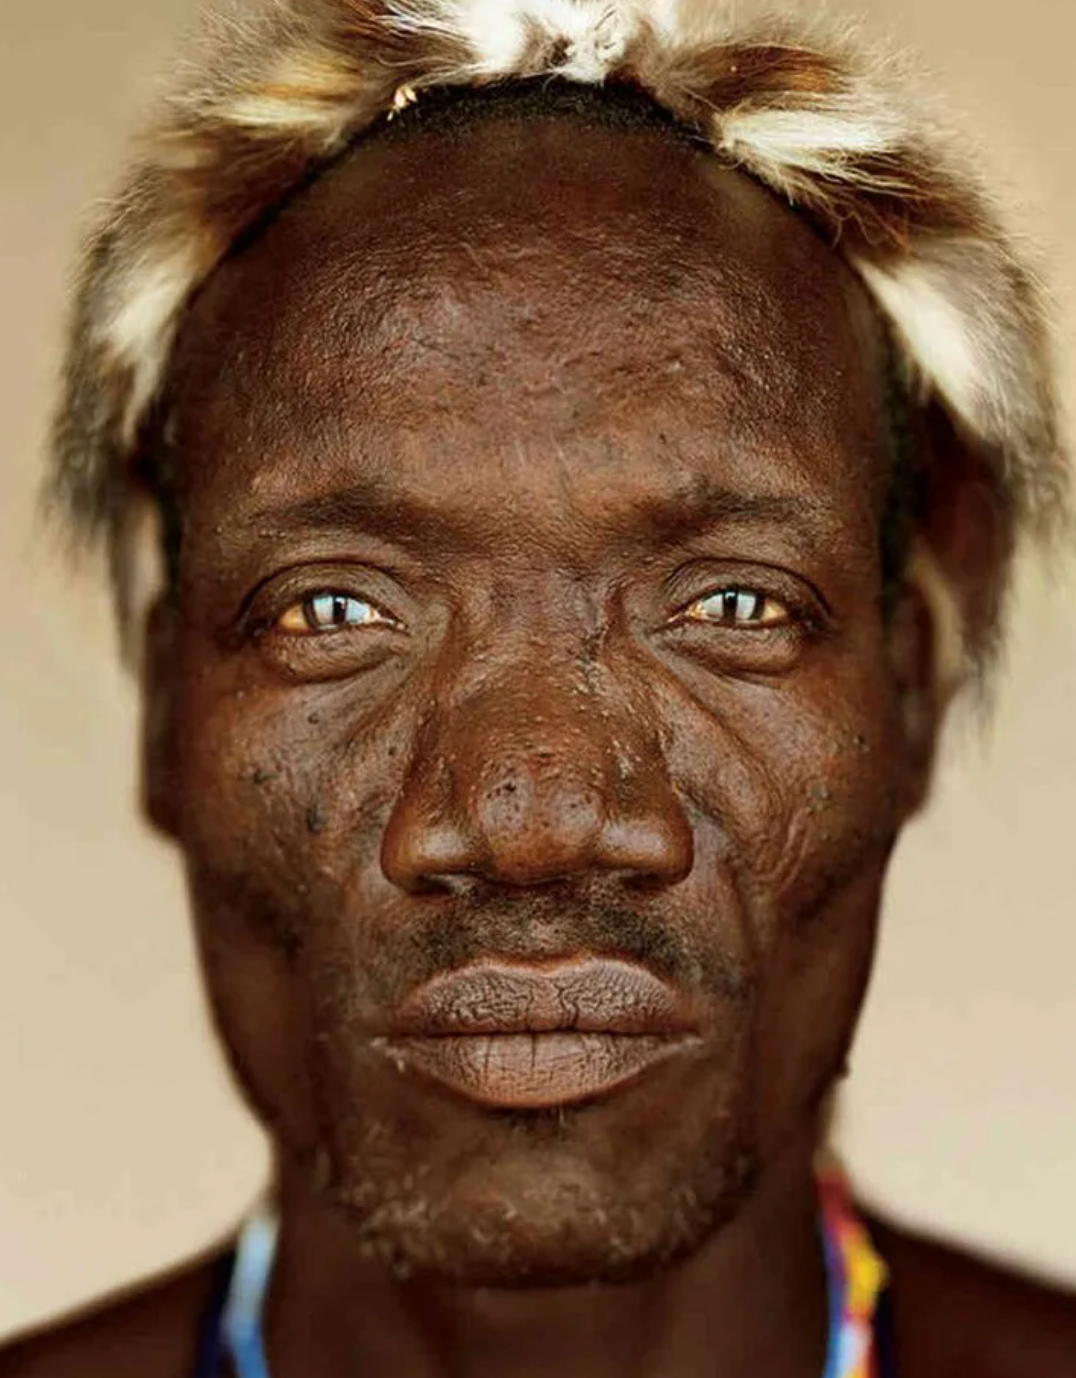

   кроп — с ним работает сеть: crop.jpg


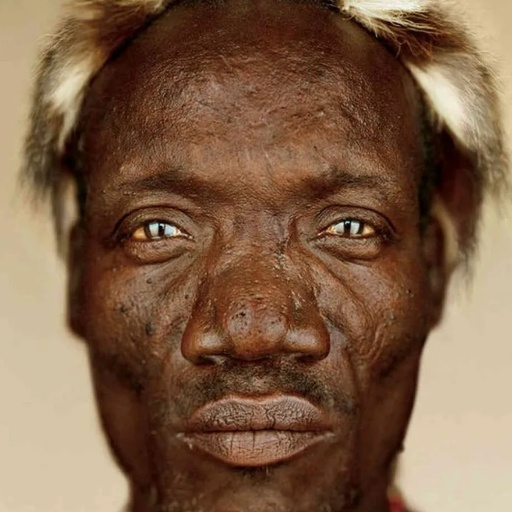

   меш поверх лица: overlay.jpg


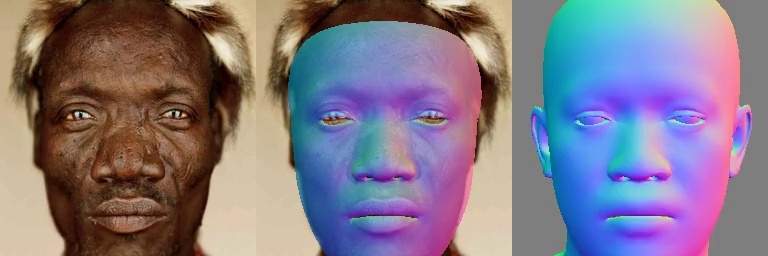

открыть в Drive: https://drive.google.com/drive/my-drive → /content/drive/MyDrive/pixel3dmm_results/Screenshot_at_Oct_28_17-01-50


In [ ]:
import base64, json, pathlib
from IPython.display import HTML, Image, display

REPORT = pathlib.Path("/content/work/demo_report.json")
if not REPORT.is_file():
    print("демо ещё не считалось — жми ▶︎ ячейку 6 (после перезапуска сессии: 1 → 2 → 3 → 4 → 5 → 6)")
else:
    rep = json.loads(REPORT.read_text(encoding="utf-8"))
    print(f"батч {rep['batch']} | статус {rep['status']} | {rep['sec']} с | режим {rep['source_mode']}")
    print(f"в Drive: {rep['drive']}")
    for photo in rep["photos"]:
        folder = pathlib.Path(rep["preview"]) / photo["folder"]
        print("=" * 64)
        name = pathlib.Path(photo["source"]).name if photo["source"] else f"кадр {photo['frame']}"
        print(f"📄 {name}  →  photos/{photo['folder']}/")
        print("   файлы: " + (", ".join(photo["files"]) or "нет"))
        if photo.get("summary"):
            print("   метрики: " + ", ".join(f"{k}={v}" for k, v in photo["summary"].items()))
        params = folder / "params.json"
        if params.is_file():
            payload = json.loads(params.read_text(encoding="utf-8"))
            print("   FLAME: " + ", ".join(f"{k}[{len(v)}]" for k, v in sorted(payload["flame"].items())))
            print("   камера/служебное: " + ", ".join(sorted(payload["camera"])))
        for title, pattern in (("исходное фото", "source.*"), ("кроп — с ним работает сеть", "crop.*"),
                               ("меш поверх лица", "overlay.*")):
            hits = sorted(p for p in folder.glob(pattern) if p.suffix.lower() in (".jpg", ".jpeg", ".png"))
            if hits:
                print(f"   {title}: {hits[0].name}")
                display(Image(filename=str(hits[0]), width=280))
    bundle = pathlib.Path(rep.get("bundle", "/content/work")) / "result.mp4"
    if bundle.is_file() and bundle.stat().st_size < 20_000_000:
        clip = base64.b64encode(bundle.read_bytes()).decode()
        display(HTML('<video controls width="480" src="data:video/mp4;base64,' + clip + '"></video>'))
    print("=" * 64)
    print("открыть в Drive: https://drive.google.com/drive/my-drive → " + str(rep["drive"]))

## 6c. test1 — то же самое на первом фото из `INPUT` (нужно только для `MODE="drive"`)
Полный цикл на одном случайном снимке корпуса, результат в `OUTPUT/batches/test1/`. В режиме загрузки
кнопкой это не нужно — там уже есть ячейка 6.

In [ ]:
import subprocess
subprocess.run(["/content/p3dmm-env/bin/python", "/content/p3dmm_pipeline.py", "test1"], check=True)

CompletedProcess(args=['/content/p3dmm-env/bin/python', '/content/p3dmm_pipeline.py', 'test1'], returncode=0)

## 7. plan — инвентаризация корпуса
Сканирует `INPUT` (одна конечная папка = один батч = один актёр), фильтрует фото без лица через FaceBoxes
(порог upstream 0.75: один плохой кадр рвёт весь батч на `run_cropping.py`), копирует фото в `/content/stage/<батч>/00000.jpg`
и пишет манифест `номер кадра → исходный файл`. План сохраняется в `OUTPUT/_state/plan.json` — после обрыва
сессии его можно не пересоздавать. При изменении `INPUT`, `OUTPUT` или фильтров пересоздай `plan`.

In [ ]:
import subprocess
subprocess.run(["/content/p3dmm-env/bin/python", "/content/p3dmm_pipeline.py", "plan"], check=True)

CompletedProcess(args=['/content/p3dmm-env/bin/python', '/content/p3dmm_pipeline.py', 'plan'], returncode=0)

## 8. run — основной прогон
Для каждого батча: предобработка → нормали → UV → трекинг → проверка артефактов по кадрам → **сразу синк в Drive**.
Гиперпараметры считаются от размера батча: `iters=100`, `global_iters=min(1500, 30·N)`, `batch_size=min(16, N)`,
`is_discontinuous=True`, `ignore_mica=True`, `save_landmarks=True`; для одного фото — `iters=800`.
При неполных артефактах предобработка повторяется до 3 раз без проблемных кадров; ошибки дочерних скриптов
останавливают текущий батч и сохраняются в журнале. Следующий `run` повторяет провальные батчи.
**Жми эту ячейку столько раз, сколько нужно**: полные готовые батчи пропускаются, работает бюджет
`SESSION_MAX_HOURS` и порог свободного места. Остановить — создать файл `/content/STOP`.

In [ ]:
import subprocess
subprocess.run(["/content/p3dmm-env/bin/python", "/content/p3dmm_pipeline.py", "run"], check=True)

CompletedProcess(args=['/content/p3dmm-env/bin/python', '/content/p3dmm_pipeline.py', 'run'], returncode=0)

## 9. status — где мы
Таблица по батчам: кадры, статус, сколько mesh/.frame/лондмарок легло на `/content`, сколько файлов в Drive.
`демо N/M` значит, что батч посчитан демо лишь частично и `run` пересчитает его целиком.

In [ ]:
import subprocess
subprocess.run(["/content/p3dmm-env/bin/python", "/content/p3dmm_pipeline.py", "status"], check=True)

FileNotFoundError: [Errno 2] No such file or directory: '/content/p3dmm-env/bin/python'

## 10. collect — индекс и итог
Собирает из `OUTPUT/batches/*/frames.csv` единый `_index/frames_all.csv` (каждый кадр → исходное фото + параметры),
пишет `_index/report.json` (батчи, число кадров, пропавшие из Drive).

In [ ]:
import subprocess
subprocess.run(["/content/p3dmm-env/bin/python", "/content/p3dmm_pipeline.py", "collect"], check=True)

CompletedProcess(args=['/content/p3dmm-env/bin/python', '/content/p3dmm_pipeline.py', 'collect'], returncode=0)

### 10b. Что легло в Drive

In [ ]:
import json, pathlib
conf = json.loads(pathlib.Path("/content/p3dmm_config.json").read_text(encoding="utf-8"))
out = pathlib.Path(conf["output"])
root = out if conf.get("source") == "upload" else out / "batches"
batches = sorted(p for p in root.glob("*") if p.is_dir() and not p.name.startswith("_")) \
    if root.is_dir() else []
print(f"результат в {root}: батчей {len(batches)}")
for folder in batches[:6]:
    files = {p.name: p.stat().st_size for p in folder.iterdir() if p.is_file()}
    per_photo = sorted(p.name for p in (folder / "photos").iterdir() if p.is_dir()) \
        if (folder / "photos").is_dir() else []
    print(f"  {folder.name:<26} фото-папок {len(per_photo):>4} | " +
          ", ".join(f"{k} {v / 1e3:.0f}К" if v < 1e6 else f"{k} {v / 1e6:.1f}М" for k, v in sorted(files.items())))
    if per_photo:
        print(f"     " + ", ".join(per_photo[:6]) + (f" ... ещё {len(per_photo) - 6}" if len(per_photo) > 6 else ""))
if len(batches) > 6:
    print(f"  ... ещё {len(batches) - 6}")
index = out / "_index/frames_all.csv"
if index.is_file():
    print(f"строк в _index/frames_all.csv: {sum(1 for _ in index.open(encoding='utf-8')) - 1}")
report = out / "_index/report.json"
if report.is_file():
    data = json.loads(report.read_text(encoding="utf-8"))
    print("итог:", json.dumps(data.get("totals", {}), ensure_ascii=False),
          "| без данных в Drive:", data.get("missing") or "нет")

результат в /content/drive/MyDrive/pixel3dmm_results: батчей 2
  Screenshot_at_Oct_28_17-01-50 фото-папок    1 | artifacts.tar.gz 617К, canonical.ply 190К, frames.csv 0К, manifest.csv 0К, metrics.json 3К, params.npz 5К, result.mp4 28К, summary.md 0К
     Screenshot at Oct 28 17-01-50
  test1                      фото-папок    1 | artifacts.tar.gz 616К, canonical.ply 190К, frames.csv 0К, manifest.csv 0К, metrics.json 3К, params.npz 5К, result.mp4 28К, summary.md 0К
     Screenshot at Oct 28 17-01-50
строк в _index/frames_all.csv: 2
итог: {"batches_in_drive": 2, "frames": 2, "log_ok": 2, "log_fail": 0, "free_gb": 87.9} | без данных в Drive: нет


### Что извлекается по каждому фото (для последующего анализа)
Папка батча: в `MODE = "upload"` — прямо `OUTPUT/<имя загруженной папки>/`, в `MODE = "drive"` —
`OUTPUT/batches/<батч>/`. Набор файлов одинаковый, отличается только глубина пути.

**`photos/<имя исходного файла>/` — своя папка на каждое фото** (имя = имя файла, кириллица сохраняется;
если два файла с одинаковым именем в разных подпапках — ко второму добавляется номер кадра: `портрет__00003`):
- **`mesh.ply`** — posed-меш этого кадра; **`canonical.ply`** рядом с папками `photos/` — общая форма актёра.
- **`checkpoint.frame`** — сырые FLAME-параметры + камера ровно в том виде, в котором их написал upstream
  (pickle, читается без CUDA).
- **`params.json`** — то же по-человечески: `flame {shape[300], exp[100], jaw[6], eyes[12], eyelids[2]}`,
  `camera {R, t, fl, pp, ...}`, `frame`, `source` (путь к исходному фото), `relpath`, `summary` с нормами.
- **`source.<ext>`** — копия исходного фото, **`crop.jpg`** — кроп, который реально видели сети,
  **`segmentation.png`** — маска лица, **`overlay.jpg`** — меш поверх лица (быстрая визуальная проверка).
- **лондмарки**: `landmarks_p3dmm.npy`, `landmarks_ibug68.ply.npy`, `landmarks_now.ply.npy`
  (upstream сохраняет их через `np.save` с расширением `.ply` — имена такие, как есть).
- **`summary.md`** — итог по фото текстом.

В папке батча кроме `photos/` лежит всё для анализа прогона целиком:
- **`frames.csv`** — по кадрам: `frame, batch, subject, angle, orig_relpath, orig_path, face_score, mesh_ply,
  frame_file, jaw_norm, exp_norm, shape_norm, t, fl, pp, note`. Это мост «номер кадра → твой исходный файл».
- **`params.npz`** — массивы по всем кадрам батча: `exp (N,100)`, `shape (N,300)`, `eyes (N,12)`, `eyelids (N,2)`,
  `jaw (N,6)`, `neck (N,6)`, `R (N,6)` + `R_rotation_matrix (N,3,3)`, `t (N,3)`, камера `R_base_0/t_base_0/fl/pp`,
  `joint_transforms`, `img_size`.
- **`manifest.csv`** — манифест staging (кадр → файл, скор лица, заметки типа `too_small_or_flat`).
- **`metrics.json`** — аргументы трекинга этого батча, **полный эффективный конфиг** (`tracking.yaml` + CLI-слияние,
  upstream `track.py` его не сохраняет), пути к предобработке, `use_flame2023`, версия torch/CUDA, модель GPU,
  список исходных фото, время.
- **`result.mp4`** — наложение меша на кадры (человекочитаемая проверка качества).
- **`artifacts.tar.gz`** — тот же меш/чекпоинты/лондмарки + предобработка (`cropped`, `seg_og`, `PIPnet_landmarks`,
  `p3dmm_normals`, `p3dmm_uv_map`) и `logs/` (tensorboard-кривые потерь, пока весят < 40 МБ) одним архивом —
  удобно скачивать для дальнейших экспериментов. `EXPORT = "bundle"` отключает разбор по фото и оставляет только его.
Плюс служебное в `OUTPUT/`: `_logs/<батч>.log` (вывод скриптов upstream), `_state/{plan.json, batch_log.jsonl,
preflight.json}`, `_index/`, а в режиме загрузки — `_uploads/` (архив исходных фото, из которого они
восстанавливаются в `/content/upload` после перезапуска рантайма).

### Типовые проблемы
- **Окно выбора файлов не открылось** (ячейка 0) — браузер мог заблокировать загрузку по кнопке, повтори ▶︎;
  в Firefox иногда нужен клик по странице сначала. Альтернатива: `MODE = "drive"` и папка в `MyDrive`.
- **Нужно загрузить папку с фото** — браузер не передаёт папки, только файлы: собери `.zip` и грузи его,
  ячейка распакует его в `/content/upload/<имя архива>/` и сохранит вложенность (папка = актёр).
  Корпус больше пары сотен фото проще положить на Drive и поставить `MODE = "drive"`.
- **«В /content/upload нет фото»** — рантайм перезапустили и `/content` очистился: ячейка 1 сама вытащит
  исходники из `OUTPUT/_uploads`. Если и там пусто (первый запуск), выполни ячейку 0 заново.
- **HEIC/WebP не загружаются** (iPhone-формат) — `files.upload()` их принимает, но пайплайн читает `.jpg/.jpeg/.png`.
  Переконвертируй: `!pip install pillow-heif -q` и пересохраняй через PIL, либо выгрузи `.jpg`.
- **Ячейка 3 молчит 20–30 мин, GPU 0%** — компиляция pytorch3d/nvdiffrast (ninja + nvcc), не зависание.
  Проверка: «Терминал» снизу → `ps aux | egrep 'ninja|cc1plus|cicc' | grep -v grep`.
- **FAIL `landmark_embedding.npy` / `FLAME_masks.pkl`** — эти файлы входят в MICA; повтори ячейку 4,
  которая восстанавливает недостающие файлы из закреплённой версии репозитория.
- **`FAIL uv.ckpt` / `Too many users have viewed or downloaded this file`** — квота Drive на файлы автора;
  ячейка 4 берёт их с HF-зеркала, просто повтори её.
- **`unsupported GNU version! gcc versions later than 11 are not supported`** при трекинге — nvdiffrast JIT-собирает
  плагин компилятором из `CC`/`CXX` запустившего процесса. В ячейке 4 и в `colab_pipeline.apply_env` они заданы;
  если запускаешь скрипт в обход пайплайна, экспортируй `CC=/content/p3dmm-env/bin/x86_64-conda-linux-gnu-gcc`,
  `CXX=...-g++`, `CUDA_HOME=/content/p3dmm-env`, `PATH=/content/p3dmm-env/bin:$PATH`.
- **`_pickle.UnpicklingError: Weights only load failed ... omegaconf.dictconfig.DictConfig`** на `network_inference.py`
  — torch 2.6+ грузит ckpt с `weights_only=True`, а в uv/normals.ckpt лежит `DictConfig`. Ставится
  `TORCH_FORCE_NO_WEIGHTS_ONLY_LOAD=1` (внутри модуля, до запуска подпроцессов).
- **`ModuleNotFoundError: No module named 'facer'`** или пикто-несовпадение API — значит скрипты поехали системным
  python'ом. Стадии должны запускаться строго `/content/p3dmm-env/bin/python ...` (ячейки 5–10 именно так и делают).
- **« батч упал: не прошли предобработку кадры …»** — в папке есть фото без лица/с низким скором (`run_cropping.py`
  бросает ValueError при score < 0.75). Включи предотсев стадии plan (`FACE_FILTER = True`) и пересоздай план.
- **«сеть не сгенерировала часть кадров»** — `network_inference.py` молча глотает ошибки по кадрам (`try/except pass`),
  поэтому пайплайн проверяет число файлов, а не код возврата; такой батч помечается провалом и перезапускается.
- **«результат есть, но в Drive не записан» (`ok_no_sync`)** — следующий `run` досылаёт его сам.
- **Сессия порвалась / `/content` очищен** — выполни ячейки 1–5, затем 8 (`run`): готовые батчи
  читаются из `OUTPUT/_state/batch_log.jsonl`, план из `OUTPUT/_state/plan.json`. Предобработка и мешки батчей
  с `/content` теряются — они и не нужны, всё уже в `artifacts.tar.gz`.
- **Мало места** — предобработка корпуса занимает ~2–3 ГБ; при `MIN_FREE_GB` цикл встаёт сам. Держи
  `keep_preproc` включённым (он по умолчанию), иначе из `artifacts.tar.gz` пропадут `cropped/`, `PIPnet_landmarks/`,
  нормали и UV.
- **В папке ракурса разные люди** — joint-стадия усреднит форму на всех; такие папки разбей до запуска.
- **Больше 1000 кадров в батче** — `tracker.py` ограничен `MAX_STEPS=1000`; пайплайн не считает
  частичный результат успешным. Разбей папку или видео на части.

In [ ]:
import json, os, subprocess

INPUT = "/content/drive/MyDrive/2pers"
OUTPUT = "/content/drive/MyDrive/pixel3dmm_results"

assert os.path.isdir(INPUT), f"Нет папки: {INPUT}"

config = {
    "input": INPUT,
    "output": OUTPUT,
    "source": "drive",
    "export": "photos",
    "demo_photos": 0,
    "subjects": "",
    "max_batches": 0,
    "face_filter": True,
    "face_min_score": 0.75,
    "use_flame2023": "auto",
    "torch_compile": False,
    "sync_to_drive": True,
    "session_max_hours": 9.0,
    "batch_timeout_min": 90,
    "min_free_gb": 2.0
}

with open("/content/p3dmm_config.json", "w") as f:
    json.dump(config, f, indent=2)

print("Конфиг записан:")
print(json.dumps(config, indent=2, ensure_ascii=False))

print("\nПапки-батчи:")
for name in sorted(os.listdir(INPUT)):
    path = os.path.join(INPUT, name)
    if os.path.isdir(path):
        photos = [
            f for f in os.listdir(path)
            if f.lower().endswith((".jpg", ".jpeg", ".png", ".webp"))
        ]
        print(f"- {name}: {len(photos)} фото")

print("\n=== PREFLIGHT ===")
result = subprocess.run(
    ["/content/p3dmm-env/bin/python", "/content/p3dmm_pipeline.py", "preflight"],
    capture_output=True,
    text=True,
)

print(result.stdout)
print(result.stderr)
print("RETURN CODE:", result.returncode)


Конфиг записан:
{
  "input": "/content/drive/MyDrive/2pers",
  "output": "/content/drive/MyDrive/pixel3dmm_results",
  "source": "drive",
  "export": "photos",
  "demo_photos": 0,
  "subjects": "",
  "max_batches": 0,
  "face_filter": true,
  "face_min_score": 0.75,
  "use_flame2023": "auto",
  "torch_compile": false,
  "sync_to_drive": true,
  "session_max_hours": 9.0,
  "batch_timeout_min": 90,
  "min_free_gb": 2.0
}

Папки-батчи:
- put: 0 фото
- udmurt: 0 фото
- vas: 0 фото

=== PREFLIGHT ===
ПРЕДФЛАЙТ — готов ли рантайм к корпусу
python   : /content/p3dmm-env/bin/python
torch    : 2.7.0+cu118 | cuda: True | Tesla T4
вес      : ok  pretrained_weights/uv.ckpt (2247 МБ)
вес      : ok  pretrained_weights/normals.ckpt (1469 МБ)
вес      : ok  src/pixel3dmm/preprocessing/MICA/data/pretrained/mica.tar (503 МБ)
вес      : ok  src/pixel3dmm/preprocessing/PIPNet/snapshots/WFLW/pip_32_16_60_r18_l2_l1_10_1_nb10/epoch59.pth (49 МБ)
flame    : ok  generic_model.pkl
flame    : ok  landmark_embedd

In [ ]:
import os

ROOT = "/content/drive/MyDrive/2pers"
EXTS = (".jpg", ".jpeg", ".png", ".webp")

for root, dirs, files in os.walk(ROOT):
    depth = root[len(ROOT):].count(os.sep)
    if depth > 3:
        dirs[:] = []
        continue
    photos = [f for f in files if f.lower().endswith(EXTS)]
    print("  " * depth + os.path.basename(root) + f"  [{len(photos)} фото]")


2pers  [0 фото]
  vas  [0 фото]
    left_mid  [16 фото]
    left_deep  [11 фото]
    left_profile  [35 фото]
    left_light  [24 фото]
    right_light  [21 фото]
    right_mid  [9 фото]
    right_deep  [16 фото]
    frontal  [78 фото]
    right_profile  [30 фото]
  udmurt  [0 фото]
    left_profile  [23 фото]
    frontal  [33 фото]
    right_mid  [10 фото]
    right_light  [12 фото]
    left_mid  [11 фото]
    left_light  [22 фото]
    left_deep  [12 фото]
    right_deep  [0 фото]
    right_profile  [16 фото]
  put  [0 фото]
    left_light  [65 фото]
    left_deep  [13 фото]
    frontal  [150 фото]
    right_light  [36 фото]
    right_deep  [11 фото]
    left_mid  [15 фото]
    right_profile  [44 фото]
    left_profile  [50 фото]
    right_mid  [19 фото]


In [ ]:
import os, shutil

ROOT = "/content/drive/MyDrive/2pers"
EXTS = (".jpg", ".jpeg", ".png", ".webp")

total = 0

for subject in sorted(os.listdir(ROOT)):
    subject_path = os.path.join(ROOT, subject)
    if not os.path.isdir(subject_path):
        continue

    copied = 0

    for angle in sorted(os.listdir(subject_path)):
        angle_path = os.path.join(subject_path, angle)
        if not os.path.isdir(angle_path):
            continue

        for file in sorted(os.listdir(angle_path)):
            if not file.lower().endswith(EXTS):
                continue

            src = os.path.join(angle_path, file)
            dst = os.path.join(subject_path, f"{angle}__{file}")

            if not os.path.exists(dst):
                shutil.copy2(src, dst)
                copied += 1

    photos = [
        f for f in os.listdir(subject_path)
        if os.path.isfile(os.path.join(subject_path, f))
        and f.lower().endswith(EXTS)
    ]

    print(f"{subject}: {len(photos)} фото, скопировано сейчас: {copied}")
    total += copied

print(f"\nВсего скопировано: {total}")


put: 403 фото, скопировано сейчас: 403
udmurt: 139 фото, скопировано сейчас: 139
vas: 240 фото, скопировано сейчас: 240

Всего скопировано: 782


In [ ]:
import os, json, subprocess

INPUT = "/content/drive/MyDrive/2pers"

# >>> ПОМЕНЯЙ ТОЛЬКО ИМЯ НОВОЙ ПАПКИ, ЕСЛИ ХОЧЕШЬ <<<
OUTPUT = "/content/drive/MyDrive/pixel3dmm_results_2pers_full"

os.makedirs(OUTPUT, exist_ok=True)

config = {
    "input": INPUT,
    "output": OUTPUT,
    "source": "drive",
    "export": "photos",
    "demo_photos": 0,
    "subjects": "",
    "max_batches": 0,
    "face_filter": True,
    "face_min_score": 0.75,
    "use_flame2023": "auto",
    "torch_compile": False,
    "sync_to_drive": True,
    "session_max_hours": 9.0,
    "batch_timeout_min": 90,
    "min_free_gb": 2.0
}

with open("/content/p3dmm_config.json", "w") as f:
    json.dump(config, f, indent=2)

print("Новая папка результатов:")
print(OUTPUT)

print("\nБатчи и фото:")
for name in sorted(os.listdir(INPUT)):
    path = os.path.join(INPUT, name)
    if os.path.isdir(path):
        photos = [
            f for f in os.listdir(path)
            if os.path.isfile(os.path.join(path, f))
            and f.lower().endswith((".jpg", ".jpeg", ".png", ".webp"))
        ]
        print(f"- {name}: {len(photos)} фото")

print("\n=== PREFLIGHT ===")
preflight = subprocess.run(
    ["/content/p3dmm-env/bin/python", "/content/p3dmm_pipeline.py", "preflight"],
    capture_output=True,
    text=True,
)

print(preflight.stdout)
print(preflight.stderr)
print("PREFLIGHT CODE:", preflight.returncode)

if preflight.returncode != 0:
    raise SystemExit("Preflight не прошёл. Обработку не запускаю.")

print("\n=== ЗАПУСК ОБРАБОТКИ ===")
run = subprocess.run(
    ["/content/p3dmm-env/bin/python", "/content/p3dmm_pipeline.py", "run"],
    capture_output=True,
    text=True,
)

# печатаем вывод по мере работы не можем, поэтому покажем его после завершения
print(run.stdout)
print(run.stderr)
print("RUN CODE:", run.returncode)


Новая папка результатов:
/content/drive/MyDrive/pixel3dmm_results_2pers_full

Батчи и фото:
- put: 403 фото
- udmurt: 139 фото
- vas: 240 фото

=== PREFLIGHT ===
ПРЕДФЛАЙТ — готов ли рантайм к корпусу
python   : /content/p3dmm-env/bin/python
torch    : 2.7.0+cu118 | cuda: True | Tesla T4
вес      : ok  pretrained_weights/uv.ckpt (2247 МБ)
вес      : ok  pretrained_weights/normals.ckpt (1469 МБ)
вес      : ok  src/pixel3dmm/preprocessing/MICA/data/pretrained/mica.tar (503 МБ)
вес      : ok  src/pixel3dmm/preprocessing/PIPNet/snapshots/WFLW/pip_32_16_60_r18_l2_l1_10_1_nb10/epoch59.pth (49 МБ)
flame    : ok  generic_model.pkl
flame    : ok  landmark_embedding.npy
flame    : ok  FLAME_masks/FLAME_masks.pkl
flame2023: НЕТ  FLAME2023/flame2023_no_jaw.pkl -> батчи пойдут с use_flame2023=False
faceboxes: ok  cpu_nms.cpython-39-x86_64-linux-gnu.so
torch.compile -> COMPILE = False
nvdiffrast: JIT-плагин собран ( gcc 11 из энва )
импорты  : ok (chumpy cv2 facer insightface pixel3dmm pytorch3d)
ди

In [ ]:
import subprocess

BASE = ["/content/p3dmm-env/bin/python", "/content/p3dmm_pipeline.py"]

print("=== PLAN ===")
plan = subprocess.run(BASE + ["plan"], capture_output=True, text=True)
print(plan.stdout)
print(plan.stderr)
print("PLAN CODE:", plan.returncode)

if plan.returncode != 0:
    raise SystemExit("Plan не прошёл. Run не запускаю.")

print("\n=== RUN ===")
run = subprocess.run(BASE + ["run"], capture_output=True, text=True)
print(run.stdout)
print(run.stderr)
print("RUN CODE:", run.returncode)


=== PLAN ===
ПЛАН — сканирование входа, фильтр лиц, staging, манифест
проверяю лица FaceBoxes (одна загрузка модели на всю выборку)...
отброшено кадров без лица/с низким скором: 2 (список в /content/work/face_dropped.json)
батч                        кадров  аргументы трекинга
put                            401  iters=100 global_iters=1500 batch_size=16 include_neck=False w_exp=0.1 use_mouth_lmk=Fal
put__frontal                   150  iters=100 global_iters=1500 batch_size=16 include_neck=False w_exp=0.1 use_mouth_lmk=Fal
put__left_deep                  13  iters=100 global_iters=390 batch_size=13 include_neck=False w_exp=0.1 use_mouth_lmk=Fals
put__left_light                 64  iters=100 global_iters=1500 batch_size=16 include_neck=False w_exp=0.1 use_mouth_lmk=Fal
put__left_mid                   15  iters=100 global_iters=450 batch_size=15 include_neck=False w_exp=0.1 use_mouth_lmk=Fals
put__left_profile               49  iters=100 global_iters=1470 batch_size=16 include_neck=False 

KeyboardInterrupt: 

In [ ]:
import os, shutil, json, subprocess

INPUT = "/content/drive/MyDrive/2pers"
RAW = "/content/drive/MyDrive/2pers_raw"
OUTPUT = "/content/drive/MyDrive/pixel3dmm_results_2pers_full"
EXTS = (".jpg", ".jpeg", ".png", ".webp")

# 1. Убираем подпапки с оригиналами, чтобы не было дублей
os.makedirs(RAW, exist_ok=True)
for subject in ["put", "udmurt", "vas"]:
    p = os.path.join(INPUT, subject)
    if not os.path.isdir(p):
        continue
    for name in os.listdir(p):
        src = os.path.join(p, name)
        if os.path.isdir(src):
            dst = os.path.join(RAW, subject, name)
            os.makedirs(os.path.dirname(dst), exist_ok=True)
            shutil.move(src, dst)

# 2. Проверяем: должны остаться только фото прямо в папках людей
print("=== ВХОД ===")
total = 0
for subject in sorted(os.listdir(INPUT)):
    p = os.path.join(INPUT, subject)
    if os.path.isdir(p):
        n = len([f for f in os.listdir(p) if f.lower().endswith(EXTS)])
        total += n
        print(f"{subject}: {n} фото")
print(f"ВСЕГО: {total} фото")

# 3. Конфиг
os.makedirs(OUTPUT, exist_ok=True)
config = {
    "input": INPUT,
    "output": OUTPUT,
    "source": "drive",
    "export": "photos",
    "demo_photos": 0,
    "subjects": "",
    "max_batches": 0,
    "face_filter": True,
    "face_min_score": 0.75,
    "use_flame2023": "auto",
    "torch_compile": False,
    "sync_to_drive": True,
    "session_max_hours": 9.0,
    "batch_timeout_min": 90,
    "min_free_gb": 2.0
}
with open("/content/p3dmm_config.json", "w") as f:
    json.dump(config, f, indent=2)

print("\n=== PREFLIGHT ===")
subprocess.run(
    ["/content/p3dmm-env/bin/python", "/content/p3dmm_pipeline.py", "preflight"]
)

# 4. План
print("\n=== PLAN ===")
plan = subprocess.run(
    ["/content/p3dmm-env/bin/python", "/content/p3dmm_pipeline.py", "plan"]
)
if plan.returncode != 0:
    raise SystemExit("PLAN не прошёл.")

# 5. Запуск обработки — с живым выводом
print("\n=== RUN ===")
run = subprocess.run(
    ["/content/p3dmm-env/bin/python", "/content/p3dmm_pipeline.py", "run"]
)
print("RUN CODE:", run.returncode)


=== ВХОД ===
put: 403 фото
udmurt: 139 фото
vas: 240 фото
ВСЕГО: 782 фото

=== PREFLIGHT ===

=== PLAN ===

=== RUN ===


In [ ]:
!nvidia-smi
